# Практическая работа №1. Анамнестические методы рекомендательных систем

**Цель:** реализовать коллаборативные рекомендательные методы, основанные на соседстве пользователей и соседстве объектов, сравнить меры сходства и выбрать наиболее подходящую.

**Предметная область — онлайн-кинотеатр.** Каталог — современные фильмы (2010–2023 гг.), пользователи — зрители, которые оценивают просмотренные фильмы по шкале от 0.5 до 5. Система решает две задачи:
1. **прогноз оценки** — какую оценку зритель поставит фильму, который ещё не смотрел;
2. **топ-N рекомендации** — какие 10 фильмов показать зрителю на главной странице.

**Анамнестические методы** (memory-based, «основанные на памяти») не строят модель заранее: они хранят всю историю оценок — «анамнез» — и при каждом запросе ищут в ней похожих пользователей или похожие фильмы. Идея простая: если зрители A и B одинаково оценили много фильмов, то фильм, понравившийся B, скорее всего понравится и A.

Два варианта метода:
- **соседство пользователей (user-based):** ищем зрителей, похожих на текущего, и рекомендуем то, что понравилось им;
- **соседство объектов (item-based):** ищем фильмы, похожие на те, что понравились зрителю, где «похожесть» фильмов определяется по оценкам всех зрителей.

План работы:
1. Подготовка матрицы оценок и базовых моделей-ориентиров.
2. Реализация пяти мер сходства и их анализ на игрушечном примере и на реальных данных.
3. Прогноз оценок и топ-N рекомендации на основе каждой меры, подбор числа соседей на валидационной выборке.
4. Итоговое сравнение на тестовой выборке и выбор лучшей меры.
5. Дополнительно: гибрид user-based + item-based, собственные методы, сравнение рекомендаций с реальными отзывами пользователей.

In [1]:
import os
import time
from functools import wraps

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil

import ml_common as mc

Оценка используемых ресурсов

In [2]:
def measure_resources(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        process = psutil.Process(os.getpid())

        start_time = time.time()
        start_memory = process.memory_info().rss / 1024**2  # MB
        result = func(*args, **kwargs)
        end_time = time.time()
        end_memory = process.memory_info().rss / 1024**2

        print(f"Время: {end_time - start_time:.2f}с")
        print(f"Память: +{end_memory - start_memory:.1f} MB (макс: {end_memory:.1f} MB)")

        return result
    return wrapper

Единый стиль графиков. Цвета серий берутся в фиксированном порядке: одна и та же мера сходства на всех графиках имеет один и тот же цвет.

In [3]:
MAIN_COLOR = "#3987e5"
PALETTE = ["#3987e5", "#d95926", "#199e70", "#c98500", "#d55181", "#008300", "#9085e9", "#e66767"]
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2,
})

# Загрузка данных

Используется срез MovieLens 32M, подготовленный в ноутбуке `00_data_preparation.ipynb`: обучающая выборка (`train`) и тестовая (`test`) — последние 20 % оценок каждого пользователя по времени.

In [4]:
data = mc.load_slice()
train_full = data["train"]
test = data["test"]
movies = data["movies"]

print(f"Обучающая выборка: {len(train_full):,} оценок")
print(f"Тестовая выборка:  {len(test):,} оценок")
print(f"Пользователей: {train_full['userId'].nunique():,}, фильмов: {len(movies):,}")

Обучающая выборка: 140,054 оценок
Тестовая выборка:  35,018 оценок
Пользователей: 1,988, фильмов: 2,191


Валидационная выборка

У методов есть параметры — например, число соседей $k$. Если подбирать их по тестовой выборке, итоговая оценка качества получится завышенной: мы фактически подгоним метод под тест. Поэтому обучающая выборка делится ещё раз тем же способом: последние 20 % оценок каждого пользователя из `train` становятся **валидационной** выборкой.

Порядок работы:
- параметры подбираются на паре `train_fit → valid`;
- итоговое качество измеряется один раз на паре `train_full → test` с уже выбранными параметрами.

Оба этапа устроены одинаково: «по прошлому пользователя предсказать его следующие оценки».

In [5]:
train_fit, valid = mc.temporal_split(train_full, test_ratio=0.2)

print(f"train_fit: {len(train_fit):,} оценок")
print(f"valid:     {len(valid):,} оценок")
print(f"train_full: {len(train_full):,} оценок")
print(f"test:       {len(test):,} оценок")

train_fit: 112,064 оценок
valid:     27,990 оценок
train_full: 140,054 оценок
test:       35,018 оценок


# Матрица оценок

Все методы работают с матрицей «пользователь × фильм» $R$, где $r_{ui}$ — оценка пользователя $u$ фильму $i$. В срезе около 2 тыс. пользователей и 2 тыс. фильмов, поэтому матрица хранится в плотном виде (массив numpy): так все меры сходства считаются матричными операциями без циклов по парам.

Вспомогательные матрицы:
- $M$ — маска: $m_{ui} = 1$, если оценка есть, иначе 0. Отсутствующая оценка в $R$ записывается нулём — это однозначно, потому что минимальная оценка 0.5;
- $L$ — «понравилось»: $l_{ui} = 1$, если $r_{ui} \ge 4$. Тот же порог используется для релевантности в метриках;
- средние оценки пользователей $\bar r_u$ и фильмов $\bar r_i$, популярность фильма (сколько раз он понравился).

Индексы строк и столбцов одинаковы для обоих этапов (`train_fit` и `train_full`): строки — все пользователи среза, столбцы — все фильмы среза.

In [6]:
user_ids = np.sort(pd.concat([train_full["userId"], test["userId"]]).unique())
movie_ids = np.sort(movies["movieId"].unique())
user_index = pd.Index(user_ids)
movie_index = pd.Index(movie_ids)
n_users, n_movies = len(user_ids), len(movie_ids)

BIAS_REG = 10   # регуляризация смещений базовой модели


def build_matrices(ratings):
    R = np.zeros((n_users, n_movies))
    rows = user_index.get_indexer(ratings["userId"])
    cols = movie_index.get_indexer(ratings["movieId"])
    R[rows, cols] = ratings["rating"].to_numpy()
    M = (R > 0).astype(float)
    return R, M


def prepare(train_part):
    # Всё, что нужно методам на одном этапе: матрицы, средние, смещения, популярность
    R, M = build_matrices(train_part)
    L = ((R >= mc.RELEVANCE_THRESHOLD) & (M > 0)).astype(float)
    global_mean = train_part["rating"].mean()

    n_u, n_i = M.sum(axis=1), M.sum(axis=0)
    user_mean = np.divide(R.sum(axis=1), n_u, out=np.full(n_users, global_mean), where=n_u > 0)
    item_mean = np.divide(R.sum(axis=0), n_i, out=np.full(n_movies, global_mean), where=n_i > 0)

    # Смещения базовой модели r = mu + b_u + b_i (с регуляризацией)
    b_i = ((R - global_mean) * M).sum(axis=0) / (BIAS_REG + n_i)
    b_u = ((R - global_mean - b_i) * M).sum(axis=1) / (BIAS_REG + n_u)

    # Сколько сессий назад выставлена оценка (0 - последняя сессия пользователя)
    sessions = mc.assign_sessions(train_part)
    sessions["back"] = sessions.groupby("userId")["session"].transform("max") - sessions["session"]
    B = np.zeros((n_users, n_movies))
    B[user_index.get_indexer(sessions["userId"]), movie_index.get_indexer(sessions["movieId"])] = sessions["back"]

    return {
        "R": R, "M": M, "L": L, "B": B,
        "global_mean": global_mean, "user_mean": user_mean, "item_mean": item_mean,
        "b_u": b_u, "b_i": b_i,
        "popularity": L.sum(axis=0),
    }


fit = prepare(train_fit)
full = prepare(train_full)

print(f"Размер матрицы: {n_users} x {n_movies}")
print(f"Плотность train_fit:  {fit['M'].mean():.2%}")
print(f"Плотность train_full: {full['M'].mean():.2%}")
print(f"Объём одной матрицы в памяти: {full['R'].nbytes / 1024**2:.1f} MB")

Размер матрицы: 1988 x 2191
Плотность train_fit:  2.57%
Плотность train_full: 3.22%
Объём одной матрицы в памяти: 33.2 MB


Фрагмент матрицы оценок: 40 самых активных пользователей и 40 самых популярных фильмов. Даже в самом «плотном» углу матрицы много пропусков (белые клетки), а в целом заполнено лишь несколько процентов.

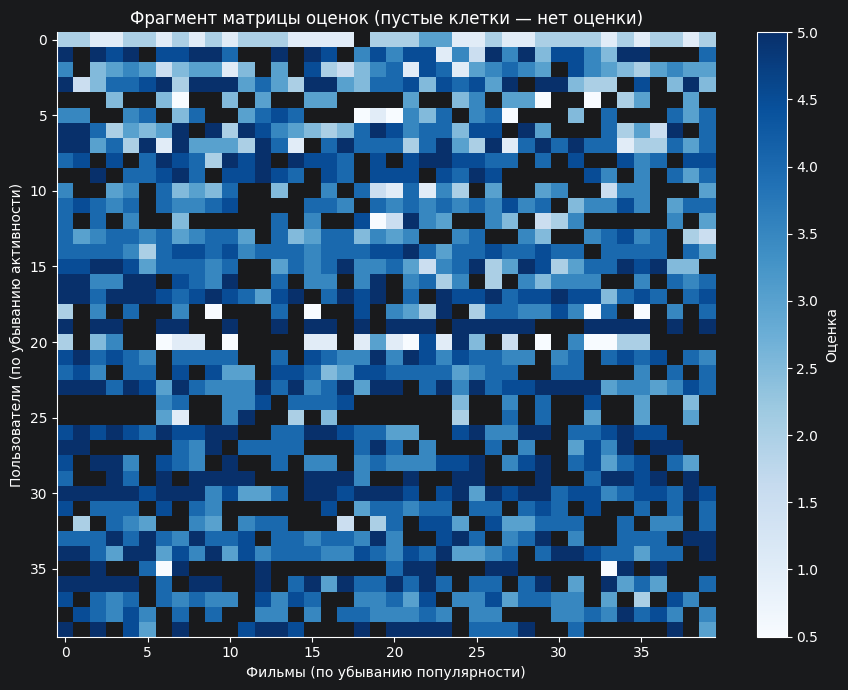

Заполнено клеток во фрагменте: 71.3%


In [7]:
top_users = np.argsort(-full["M"].sum(axis=1))[:40]
top_movies = np.argsort(-full["M"].sum(axis=0))[:40]
fragment = np.where(full["M"][np.ix_(top_users, top_movies)] > 0,
                    full["R"][np.ix_(top_users, top_movies)], np.nan)

plt.figure(figsize=(9, 7))
image = plt.imshow(fragment, cmap="Blues", vmin=0.5, vmax=5, aspect="auto")
plt.colorbar(image, label="Оценка")
plt.title("Фрагмент матрицы оценок (пустые клетки — нет оценки)")
plt.xlabel("Фильмы (по убыванию популярности)")
plt.ylabel("Пользователи (по убыванию активности)")
plt.grid(False)
plt.tight_layout()
plt.show()

print(f"Заполнено клеток во фрагменте: {np.isfinite(fragment).mean():.1%}")

# Базовые модели

Прежде чем сравнивать меры сходства, нужны **ориентиры** — простые методы без поиска соседей. Если сложный метод их не превосходит, его сложность не оправдана.

Для прогноза оценки:
- **глобальное среднее** $\hat r_{ui} = \mu$ — одна оценка для всех;
- **среднее пользователя** $\hat r_{ui} = \bar r_u$ — учитывает «щедрость» зрителя;
- **среднее фильма** $\hat r_{ui} = \bar r_i$ — учитывает качество фильма;
- **базовая модель со смещениями** $\hat r_{ui} = \mu + b_u + b_i$, где $b_i$ — насколько фильм оценивают выше среднего, $b_u$ — насколько пользователь щедрее среднего. Смещения считаются с регуляризацией $\lambda$, чтобы фильм с одной оценкой 5 не получал огромное смещение:
$$b_i = \frac{\sum_u (r_{ui} - \mu)}{\lambda + n_i}, \qquad b_u = \frac{\sum_i (r_{ui} - \mu - b_i)}{\lambda + n_u}.$$

Для топ-N рекомендаций:
- **популярное** — всем пользователям одни и те же фильмы, которые чаще всего нравились;
- **случайное** — нижняя граница качества.

Метрики (функции из `ml_common`):
- **MAE, RMSE** — ошибка прогноза оценки в баллах;
- **Precision@10, Recall@10, NDCG@10** — качество списка из 10 рекомендаций; фильм релевантен, если пользователь потом оценил его не ниже 4;
- **покрытие каталога** — доля фильмов, которые попали хотя бы в один список рекомендаций. Низкое покрытие означает, что система всем советует одно и то же.

In [8]:
TOP_N = 10
results = []   # сюда собираются все результаты для итоговых таблиц


def eval_pairs(eval_df):
    return (user_index.get_indexer(eval_df["userId"]),
            movie_index.get_indexer(eval_df["movieId"]),
            eval_df["rating"].to_numpy())


def baseline_prediction(phase, u_idx, i_idx):
    return phase["global_mean"] + phase["b_u"][u_idx] + phase["b_i"][i_idx]


def evaluate_prediction(pred, phase, u_idx, i_idx, y_true):
    # Пропуски (нет соседей) заменяются прогнозом базовой модели
    coverage = np.isfinite(pred).mean()
    pred = np.where(np.isfinite(pred), pred, baseline_prediction(phase, u_idx, i_idx))
    pred = np.clip(pred, 0.5, 5.0)
    return {"MAE": mc.mae(y_true, pred), "RMSE": mc.rmse(y_true, pred), "Покрытие прогноза": coverage}


def recommend(scores, phase, n=TOP_N):
    # Топ-N по матрице оценок релевантности; уже оценённые фильмы исключаются.
    # Крошечная добавка популярности разрешает ничьи (например, нулевые оценки у
    # пользователя без соседей) в пользу популярных фильмов.
    scores = scores + 1e-6 * phase["popularity"] / phase["popularity"].max()
    scores = np.where(phase["M"] > 0, -np.inf, scores)
    top = np.argpartition(-scores, n, axis=1)[:, :n]
    order = np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1)
    top = np.take_along_axis(top, order, axis=1)
    return {user_ids[u]: movie_ids[top[u]].tolist() for u in range(n_users)}


def evaluate_topn(recs, eval_df, n=TOP_N):
    metrics = mc.ranking_metrics(recs, eval_df, k=n)
    metrics.pop("users")
    eval_users = eval_df["userId"].unique()
    recommended = set()
    for user in eval_users:
        recommended.update(recs[user][:n])
    metrics["Покрытие каталога"] = len(recommended) / n_movies
    return metrics

Оценка базовых моделей на валидационной и тестовой выборках

In [9]:
def evaluate_baselines(phase, eval_df, stage):
    u_idx, i_idx, y = eval_pairs(eval_df)
    predictions = {
        "Глобальное среднее": np.full(len(y), phase["global_mean"]),
        "Среднее пользователя": phase["user_mean"][u_idx],
        "Среднее фильма": phase["item_mean"][i_idx],
        "Смещения mu + b_u + b_i": baseline_prediction(phase, u_idx, i_idx),
    }
    rows = []
    for name, pred in predictions.items():
        rows.append({"Этап": stage, "Метод": name, "Подход": "Базовый",
                     **evaluate_prediction(pred, phase, u_idx, i_idx, y)})

    rng = np.random.default_rng(42)
    scores = {
        "Популярное": np.tile(phase["popularity"], (n_users, 1)),
        "Случайное": rng.random((n_users, n_movies)),
    }
    for name, score in scores.items():
        rows.append({"Этап": stage, "Метод": name, "Подход": "Базовый",
                     **evaluate_topn(recommend(score, phase), eval_df)})
    return rows


results += evaluate_baselines(fit, valid, "valid")
results += evaluate_baselines(full, test, "test")

baselines = pd.DataFrame(results)
print("БАЗОВЫЕ МОДЕЛИ (валидация):")
print(baselines[baselines["Этап"] == "valid"].drop(columns=["Этап", "Подход"]).round(4).to_string(index=False))

БАЗОВЫЕ МОДЕЛИ (валидация):
                  Метод    MAE   RMSE  Покрытие прогноза  Precision@10  Recall@10  NDCG@10  Покрытие каталога
     Глобальное среднее 0.8023 1.0570                1.0           NaN        NaN      NaN                NaN
   Среднее пользователя 0.6700 0.9042                1.0           NaN        NaN      NaN                NaN
         Среднее фильма 0.7544 1.0014                1.0           NaN        NaN      NaN                NaN
Смещения mu + b_u + b_i 0.6270 0.8461                1.0           NaN        NaN      NaN                NaN
             Популярное    NaN    NaN                NaN        0.0517     0.0926   0.0805             0.0397
              Случайное    NaN    NaN                NaN        0.0032     0.0043   0.0041             1.0000


Базовые модели задают планку: метод на основе соседства должен давать MAE ниже, чем модель со смещениями, а NDCG@10 — выше, чем рекомендации популярного. Популярное обычно оказывается сильным соперником: при временном разбиении многие пользователи действительно смотрят и высоко оценивают хиты.

# Меры сходства

Каждый пользователь — это вектор оценок длины «число фильмов» (большинство координат пусты). Мера сходства по двум таким векторам возвращает число: чем оно больше, тем пользователи считаются ближе. Для item-based те же меры применяются к столбцам матрицы: фильм — вектор оценок всех пользователей.

Обозначения: $I_u$ — множество фильмов, оценённых пользователем $u$; $I_{uv} = I_u \cap I_v$ — общие фильмы двух пользователей.

**Выбранные меры.** Реализованы пять мер из двух семейств. Они по-разному отвечают на вопрос «что значит похожие зрители».

Семейство 1 — сходство **по значениям оценок** («одинаково оценивают»):

1. **Коэффициент корреляции Пирсона** по общим фильмам:
$$s(u,v) = \frac{\sum_{i \in I_{uv}} (r_{ui} - \bar r_u)(r_{vi} - \bar r_v)}{\sqrt{\sum_{i \in I_{uv}} (r_{ui} - \bar r_u)^2}\,\sqrt{\sum_{i \in I_{uv}} (r_{vi} - \bar r_v)^2}}, \quad \bar r_u, \bar r_v \text{ — средние по } I_{uv}.$$
Выбран потому, что **вычитает среднее пользователя**: «щедрый» зритель, ставящий всем 4–5, и «строгий», ставящий 2–3, но в том же порядке предпочтений, окажутся похожими. Анализ данных в ноутбуке 00 показал, что у пользователей разная «точка отсчёта», поэтому эта мера здесь особенно уместна. Значения от −1 (противоположные вкусы) до 1.

2. **Косинусная мера** — косинус угла между векторами оценок (пропуски считаются нулями):
$$s(u,v) = \frac{\sum_i r_{ui} r_{vi}}{\sqrt{\sum_{i \in I_u} r_{ui}^2}\,\sqrt{\sum_{i \in I_v} r_{vi}^2}}.$$
Выбрана как самая распространённая и быстрая мера. В отличие от Пирсона, она не учитывает смещение оценок, но зато нормы берутся по **всем** оценкам пользователя, поэтому пара с малым числом общих фильмов автоматически получает малое сходство.

3. **Евклидово расстояние (Lp-норма при p = 2)** по общим фильмам, переведённое в сходство:
$$d(u,v) = \left(\frac{1}{|I_{uv}|} \sum_{i \in I_{uv}} |r_{ui} - r_{vi}|^p\right)^{1/p}, \qquad s(u,v) = \frac{1}{1 + d(u,v)}.$$
Выбрано как представитель мер-расстояний из методички: зрители похожи, если их оценки **численно близки**. Деление на $|I_{uv}|$ нужно, чтобы расстояние не росло просто от числа общих фильмов. Частные случаи Lp-нормы: $p = 1$ — манхэттенское расстояние, $p = \infty$ — расстояние Чебышева (максимальное расхождение). Для основных расчётов взято $p = 2$: его можно вычислить матричными операциями для всех пар сразу.

Семейство 2 — сходство **по факту оценивания** («смотрят одно и то же»), сами значения оценок не учитываются:

4. **Коэффициент Жаккара** — доля общих фильмов среди всех фильмов двух пользователей:
$$s(u,v) = \frac{|I_u \cap I_v|}{|I_u \cup I_v|}.$$

5. **Коэффициент Отиаи** (Ochiai, он же косинус для двоичных векторов):
$$s(u,v) = \frac{|I_u \cap I_v|}{\sqrt{|I_u| \cdot |I_v|}}.$$
Отличие от Жаккара: Жаккар сильно штрафует пары, где один пользователь оценил намного больше фильмов, чем другой; Отиаи штрафует такие пары мягче.

Меры второго семейства выбраны потому, что задача онлайн-кинотеатра — не только угадать оценку, но и угадать, **что зритель вообще захочет посмотреть**. Сам выбор фильма для просмотра несёт информацию о вкусе, даже без оценки.

**Вычисление для всех пар сразу.** Суммы по общим фильмам выражаются через произведения матриц: например, $N = M M^T$ — число общих фильмов для каждой пары, $R R^T$ — сумма произведений оценок по общим фильмам, $(R \circ R)\,M^T$ — сумма квадратов оценок первого пользователя по фильмам, которые оценил и второй. Из этих матриц все пять мер получаются без циклов по парам.

In [10]:
def sim_pearson(R, M, min_common=2):
    # Корреляция Пирсона по общим объектам через суммы:
    # r = (N*Sxy - Sx*Sy) / sqrt((N*Sxx - Sx^2) * (N*Syy - Sy^2))
    N = M @ M.T
    Sx = R @ M.T                 # сумма оценок первого по общим объектам
    Sxx = (R * R) @ M.T          # сумма квадратов оценок первого по общим объектам
    Sxy = R @ R.T                # сумма произведений оценок по общим объектам
    num = N * Sxy - Sx * Sx.T
    var = np.clip(N * Sxx - Sx ** 2, 0, None)
    den = np.sqrt(var * var.T)
    S = np.divide(num, den, out=np.zeros_like(num), where=den > 1e-9)
    S[N < min_common] = 0
    np.fill_diagonal(S, 0)
    return np.clip(S, -1, 1).astype(np.float32)


def sim_cosine(R, M):
    norms = np.sqrt((R * R).sum(axis=1))
    den = np.outer(norms, norms)
    S = np.divide(R @ R.T, den, out=np.zeros_like(den), where=den > 0)
    np.fill_diagonal(S, 0)
    return S.astype(np.float32)


def sim_euclidean(R, M, min_common=1):
    # Среднеквадратичное расстояние по общим объектам: (Sxx + Syy - 2*Sxy) / N
    N = M @ M.T
    Sxx = (R * R) @ M.T
    D2 = np.clip(Sxx + Sxx.T - 2 * (R @ R.T), 0, None)
    msd = np.divide(D2, N, out=np.zeros_like(D2), where=N > 0)
    S = np.where(N >= min_common, 1 / (1 + np.sqrt(msd)), 0)
    np.fill_diagonal(S, 0)
    return S.astype(np.float32)


def sim_jaccard(R, M):
    inter = M @ M.T
    counts = M.sum(axis=1)
    union = counts[:, None] + counts[None, :] - inter
    S = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
    np.fill_diagonal(S, 0)
    return S.astype(np.float32)


def sim_ochiai(R, M):
    inter = M @ M.T
    counts = M.sum(axis=1)
    den = np.sqrt(np.outer(counts, counts))
    S = np.divide(inter, den, out=np.zeros_like(inter), where=den > 0)
    np.fill_diagonal(S, 0)
    return S.astype(np.float32)


MEASURES = {
    "Пирсон": sim_pearson,
    "Косинус": sim_cosine,
    "Евклид (L2)": sim_euclidean,
    "Жаккар": sim_jaccard,
    "Отиаи": sim_ochiai,
}
MEASURE_COLORS = {name: PALETTE[i] for i, name in enumerate(MEASURES)}
MEASURE_MARKERS = {name: MARKERS[i] for i, name in enumerate(MEASURES)}

Проверка на игрушечном примере

Прежде чем применять меры к реальным данным, проверим их на маленькой матрице, где результат можно оценить в уме. Четыре зрителя оценили пять фильмов:
- Анна и Борис любят научную фантастику («Начало», «Интерстеллар») и оценили её одинаково;
- Вера, наоборот, не любит фантастику и любит мультфильмы;
- Глеб оценил всего один фильм — так же, как Анна.

In [11]:
toy_movies = ["Начало", "Интерстеллар", "Джокер", "Головоломка", "Холодное сердце"]
toy_users = ["Анна", "Борис", "Вера", "Глеб"]
toy = pd.DataFrame([
    [4, 5, 4, np.nan, 1],
    [4, 5, np.nan, 2, np.nan],
    [2, 1, np.nan, 5, 5],
    [4, np.nan, np.nan, np.nan, np.nan],
], index=toy_users, columns=toy_movies)
print(toy, "\n")

toy_M = toy.notna().to_numpy(dtype=float)
toy_R = toy.fillna(0).to_numpy()

for name, func in MEASURES.items():
    S = func(toy_R, toy_M)
    print(f"{name}:")
    print(pd.DataFrame(S, index=toy_users, columns=toy_users).round(3), "\n")

       Начало  Интерстеллар  Джокер  Головоломка  Холодное сердце
Анна        4           5.0     4.0          NaN              1.0
Борис       4           5.0     NaN          2.0              NaN
Вера        2           1.0     NaN          5.0              5.0
Глеб        4           NaN     NaN          NaN              NaN 

Пирсон:
       Анна  Борис   Вера  Глеб
Анна    0.0  1.000 -1.000   0.0
Борис   1.0  0.000 -0.996   0.0
Вера   -1.0 -0.996  0.000   0.0
Глеб    0.0  0.000  0.000   0.0 

Косинус:
        Анна  Борис   Вера   Глеб
Анна   0.000  0.803  0.319  0.525
Борис  0.803  0.000  0.462  0.596
Вера   0.319  0.462  0.000  0.270
Глеб   0.525  0.596  0.270  0.000 

Евклид (L2):
        Анна  Борис   Вера   Глеб
Анна   0.000  1.000  0.224  1.000
Борис  1.000  0.000  0.243  1.000
Вера   0.224  0.243  0.000  0.333
Глеб   1.000  1.000  0.333  0.000 

Жаккар:
       Анна  Борис  Вера   Глеб
Анна   0.00  0.400  0.60  0.250
Борис  0.40  0.000  0.75  0.333
Вера   0.60  0.750  0.00  0.

Что видно на примере:
- **Пирсон** правильно находит, что Анна и Борис совпадают по вкусу (1.0), а Вера — их противоположность (отрицательное значение). Для Глеба значение 0: по одному общему фильму корреляцию посчитать нельзя;
- **Косинус** даёт Анне и Вере положительное сходство, хотя их вкусы противоположны. Причина в том, что все оценки положительны (от 0.5 до 5), и векторы никогда не смотрят в противоположные стороны. Это главный недостаток косинуса для оценок;
- **Евклид** считает Анну и Глеба **идеально похожими** (1.0) по единственному общему фильму. Это опасно: случайное совпадение одной оценки делает пользователя «лучшим соседом». К этой проблеме мы ещё вернёмся;
- **Жаккар и Отиаи** видят только факт оценивания: Анна и Вера для них похожи, ведь они оценили три общих фильма. Противоположность вкусов эти меры не различают — зато они устойчивы и не зависят от шкалы.

Lp-норма при разных p для пары «Анна — Вера» (три общих фильма с расхождениями 2, 4 и 4 балла):

In [12]:
def lp_distance(x, y, p):
    common = ~(np.isnan(x) | np.isnan(y))
    diff = np.abs(x[common] - y[common])
    if np.isinf(p):
        return diff.max()                                  # Чебышев
    return (np.mean(diff ** p)) ** (1 / p)


anna, vera = toy.loc["Анна"].to_numpy(), toy.loc["Вера"].to_numpy()
for p, title in [(1, "Манхэттен (p=1)"), (2, "Евклид (p=2)"), (np.inf, "Чебышев (p=inf)")]:
    d = lp_distance(anna, vera, p)
    print(f"{title:18}: d = {d:.3f}, сходство 1/(1+d) = {1 / (1 + d):.3f}")

Манхэттен (p=1)   : d = 3.333, сходство 1/(1+d) = 0.231
Евклид (p=2)      : d = 3.464, сходство 1/(1+d) = 0.224
Чебышев (p=inf)   : d = 4.000, сходство 1/(1+d) = 0.200


Чем больше $p$, тем сильнее расстояние определяется самым большим расхождением: при $p = 1$ все расхождения учитываются одинаково, при $p = \infty$ — только максимальное.

Расчёт мер на реальных данных

Матрицы сходства считаются для обоих этапов (`fit` — для подбора параметров, `full` — для итоговой проверки) и для обоих подходов: пользователи сравниваются по строкам $R$, фильмы — по столбцам ($R^T$).

In [13]:
@measure_resources
def compute_similarities(phase, orientation):
    R, M = (phase["R"], phase["M"]) if orientation == "user" else (phase["R"].T, phase["M"].T)
    result = {}
    for name, func in MEASURES.items():
        start = time.time()
        result[name] = func(R, M)
        print(f"  {name:12}: {time.time() - start:.2f}с")
    return result


print("Сходство пользователей (fit):")
user_sims_fit = compute_similarities(fit, "user")
print("\nСходство фильмов (fit):")
item_sims_fit = compute_similarities(fit, "item")
print("\nСходство пользователей (full):")
user_sims_full = compute_similarities(full, "user")
print("\nСходство фильмов (full):")
item_sims_full = compute_similarities(full, "item")

Сходство пользователей (fit):
  Пирсон      : 0.50с
  Косинус     : 0.08с
  Евклид (L2) : 0.30с
  Жаккар      : 0.08с
  Отиаи       : 0.08с
Время: 1.04с
Память: +87.8 MB (макс: 573.0 MB)

Сходство фильмов (fit):
  Пирсон      : 0.47с
  Косинус     : 0.20с
  Евклид (L2) : 0.56с
  Жаккар      : 0.32с
  Отиаи       : 0.13с
Время: 1.69с
Память: +92.5 MB (макс: 665.5 MB)

Сходство пользователей (full):
  Пирсон      : 0.90с
  Косинус     : 0.40с
  Евклид (L2) : 0.33с
  Жаккар      : 0.09с
  Отиаи       : 0.08с
Время: 1.80с
Память: +75.5 MB (макс: 741.0 MB)

Сходство фильмов (full):
  Пирсон      : 1.54с
  Косинус     : 0.29с
  Евклид (L2) : 0.36с
  Жаккар      : 0.31с
  Отиаи       : 0.32с
Время: 2.81с
Память: +91.8 MB (макс: 832.8 MB)


# Анализ мер сходства

Сколько общих фильмов у пары пользователей

Надёжность любой меры зависит от того, по скольким общим фильмам она посчитана. Посмотрим на распределение этого числа.

Число общих фильмов у пары пользователей:
  0         : 5.9% пар
  1         : 7.8% пар
  2-4       : 24.3% пар
  5-19      : 49.5% пар
  20 и более: 12.5% пар
Медиана: 6, среднее: 9.9


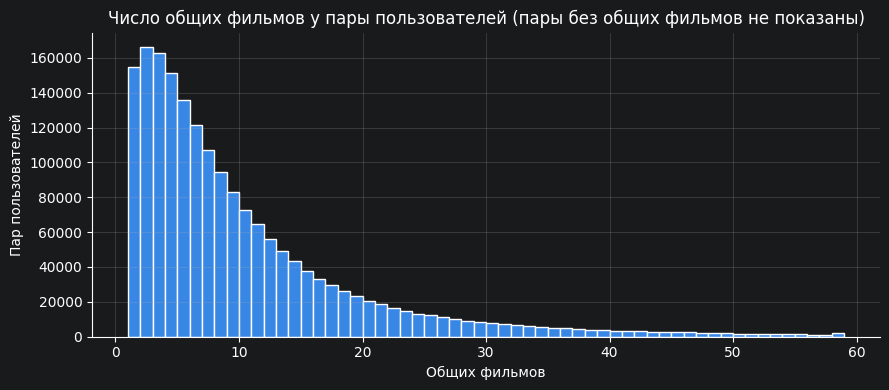

In [14]:
N_users = full["M"] @ full["M"].T
upper = np.triu_indices(n_users, k=1)
common = N_users[upper]

print("Число общих фильмов у пары пользователей:")
for low, high, label in [(0, 0, "0"), (1, 1, "1"), (2, 4, "2-4"), (5, 19, "5-19"), (20, np.inf, "20 и более")]:
    share = ((common >= low) & (common <= high)).mean()
    print(f"  {label:10}: {share:.1%} пар")
print(f"Медиана: {np.median(common):.0f}, среднее: {common.mean():.1f}")

plt.figure(figsize=(9, 4))
plt.hist(common[common > 0], bins=np.arange(1, 60), color=MAIN_COLOR, edgecolor="white")
plt.title("Число общих фильмов у пары пользователей (пары без общих фильмов не показаны)")
plt.xlabel("Общих фильмов")
plt.ylabel("Пар пользователей")
plt.tight_layout()
plt.show()

Если у заметной доли пар всего 1–4 общих фильма, то значения Пирсона и Евклида для них почти случайны: как показал игрушечный пример, одна совпавшая оценка даёт Евклиду максимальное сходство. Меры с нормировкой по всем оценкам пользователя (косинус, Жаккар, Отиаи) от этого защищены лучше.

Распределение значений сходства

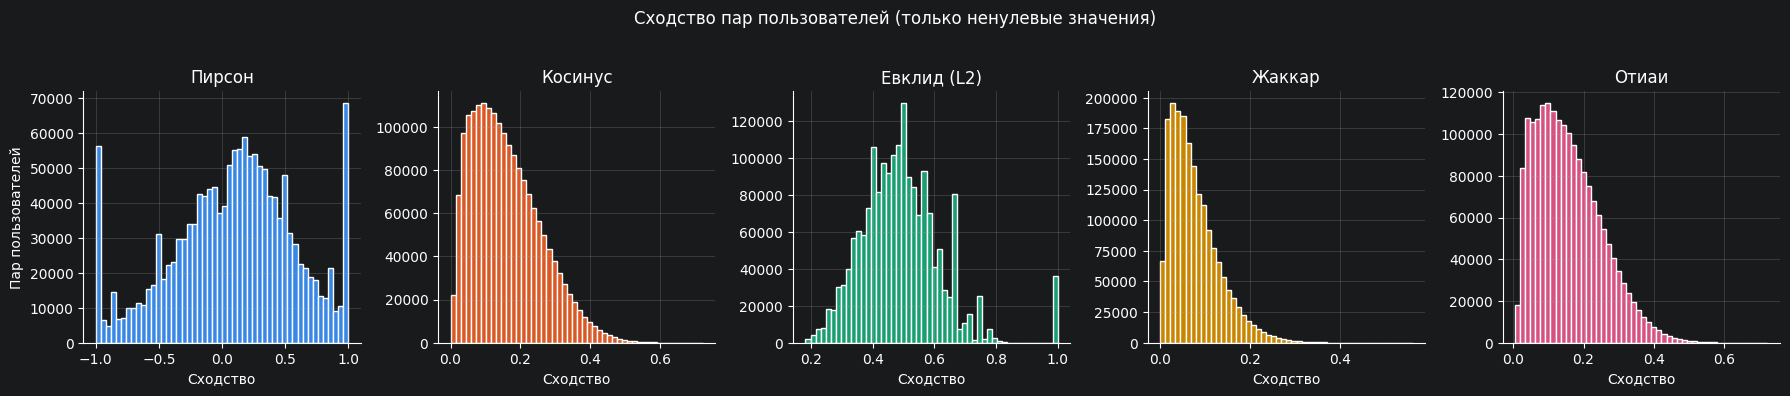

Пирсон      : ненулевых 76.4%, отрицательных 30.4%, медиана ненулевых 0.127
Косинус     : ненулевых 94.1%, отрицательных 0.0%, медиана ненулевых 0.143
Евклид (L2) : ненулевых 94.1%, отрицательных 0.0%, медиана ненулевых 0.484
Жаккар      : ненулевых 94.1%, отрицательных 0.0%, медиана ненулевых 0.065
Отиаи       : ненулевых 94.1%, отрицательных 0.0%, медиана ненулевых 0.143


In [15]:
fig, axes = plt.subplots(1, len(MEASURES), figsize=(18, 3.8))
for ax, (name, S) in zip(axes, user_sims_full.items()):
    values = S[upper]
    values = values[values != 0]
    ax.hist(values, bins=50, color=MEASURE_COLORS[name], edgecolor="white")
    ax.set_title(name)
    ax.set_xlabel("Сходство")
axes[0].set_ylabel("Пар пользователей")
plt.suptitle("Сходство пар пользователей (только ненулевые значения)", y=1.03)
plt.tight_layout()
plt.show()

for name, S in user_sims_full.items():
    values = S[upper]
    print(f"{name:12}: ненулевых {np.mean(values != 0):.1%}, отрицательных {np.mean(values < 0):.1%}, "
          f"медиана ненулевых {np.median(values[values != 0]):.3f}")

Насколько меры согласны друг с другом

Для рекомендаций важны не сами значения сходства, а **порядок соседей**: кто окажется в числе $k$ ближайших. Поэтому меры сравниваются ранговой корреляцией Спирмена по парам пользователей, имеющим хотя бы один общий фильм. Корреляция близка к 1 — меры выбирают почти одних и тех же соседей; близка к 0 — меры видят «похожесть» по-разному.

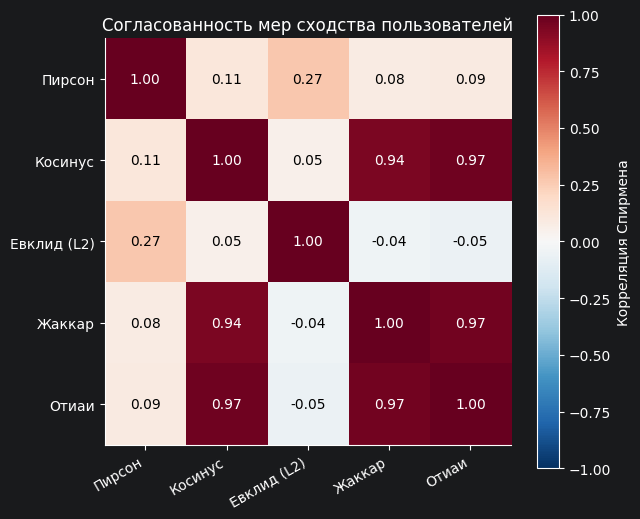

In [16]:
rng = np.random.default_rng(42)
pairs_with_common = np.flatnonzero(common > 0)
sample = rng.choice(pairs_with_common, size=min(200_000, len(pairs_with_common)), replace=False)

sample_values = pd.DataFrame({name: S[upper][sample] for name, S in user_sims_full.items()})
spearman = sample_values.corr(method="spearman")

plt.figure(figsize=(6.5, 5.5))
image = plt.imshow(spearman, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(image, label="Корреляция Спирмена")
plt.xticks(range(len(MEASURES)), spearman.columns, rotation=30, ha="right")
plt.yticks(range(len(MEASURES)), spearman.index)
for i in range(len(MEASURES)):
    for j in range(len(MEASURES)):
        value = spearman.iloc[i, j]
        plt.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color="white" if abs(value) > 0.6 else "black")
plt.title("Согласованность мер сходства пользователей")
plt.grid(False)
plt.tight_layout()
plt.show()

Ожидаемая картина: Жаккар и Отиаи почти совпадают (обе меры считают общие фильмы), косинус близок к ним, потому что тоже сильно зависит от числа общих фильмов, а Пирсон и Евклид смотрят на согласованность оценок и выбирают других соседей.

# Прогноз оценок

**User-based.** Оценка пользователя $u$ фильму $i$ прогнозируется по $k$ самым похожим на $u$ пользователям среди тех, кто оценил $i$ (множество $N_k(u, i)$). Учитываются только соседи с положительным сходством:
$$\hat r_{ui} = \bar r_u + \frac{\sum_{v \in N_k(u,i)} s(u,v)\,(r_{vi} - \bar r_v)}{\sum_{v \in N_k(u,i)} s(u,v)}.$$
Соседи передают не саму оценку, а **отклонение от своего среднего**: если строгий сосед поставил 3.5 при своём среднем 2.5, это сигнал «фильм понравился», который прибавляется к среднему пользователя $u$.

**Item-based.** Прогноз строится по $k$ фильмам, оценённым пользователем $u$ и наиболее похожим на $i$ (множество $N_k(i; u)$):
$$\hat r_{ui} = \bar r_i + \frac{\sum_{j \in N_k(i;u)} s(i,j)\,(r_{uj} - \bar r_j)}{\sum_{j \in N_k(i;u)} s(i,j)}.$$
Если пользователь оценил похожие фильмы выше их среднего, фильм $i$ тоже получит оценку выше своего среднего.

Если подходящих соседей нет, прогноз невозможен — тогда используется базовая модель $\mu + b_u + b_i$. Доля пар, для которых прогноз удалось построить по соседям, показана как «Покрытие прогноза».

In [17]:
def _groups_by_user(u_idx):
    order = np.argsort(u_idx, kind="stable")
    bounds = np.flatnonzero(np.diff(u_idx[order])) + 1
    return np.split(order, bounds)


def predict_user_based(phase, S, k, u_idx, i_idx):
    R, M, mu = phase["R"], phase["M"], phase["user_mean"]
    C = (R - mu[:, None]) * M                 # отклонения от среднего пользователя
    pred = np.full(len(u_idx), np.nan)
    for group in _groups_by_user(u_idx):
        u, items = u_idx[group[0]], i_idx[group]
        W = np.where(M[:, items] > 0, S[u][:, None], 0.0)   # сходство с оценившими фильм
        W[W < 0] = 0
        if k < n_users:
            kth = -np.partition(-W, k - 1, axis=0)[k - 1]   # k-е по величине сходство
            W[W < kth] = 0
        num, den = (W * C[:, items]).sum(axis=0), W.sum(axis=0)
        ok = den > 0
        pred[group[ok]] = mu[u] + num[ok] / den[ok]
    return pred


def predict_item_based(phase, S, k, u_idx, i_idx):
    R, M, mu_i = phase["R"], phase["M"], phase["item_mean"]
    pred = np.full(len(u_idx), np.nan)
    for group in _groups_by_user(u_idx):
        u, items = u_idx[group[0]], i_idx[group]
        rated = np.flatnonzero(M[u])
        if len(rated) == 0:
            continue
        W = S[np.ix_(items, rated)].astype(float)            # сходство целевых и оценённых фильмов
        W[W < 0] = 0
        if k < len(rated):
            kth = -np.partition(-W, k - 1, axis=1)[:, k - 1]
            W[W < kth[:, None]] = 0
        deviation = R[u, rated] - mu_i[rated]
        num, den = W @ deviation, W.sum(axis=1)
        ok = den > 0
        pred[group[ok]] = mu_i[items[ok]] + num[ok] / den[ok]
    return pred


PREDICTORS = {"user-based": predict_user_based, "item-based": predict_item_based}

# k, превышающее число пользователей и фильмов, означает «все соседи с положительным сходством»
ALL_NEIGHBOURS = 10_000


def k_labels(grid):
    return [str(k) if k < ALL_NEIGHBOURS else "все" for k in grid]

Подбор числа соседей $k$ на валидационной выборке

Малое $k$ — прогноз по нескольким самым похожим соседям: точный, если сходство надёжное, но шумный. Большое $k$ — усреднение по многим соседям: устойчиво, но в прогноз попадают малопохожие пользователи, и он приближается к среднему. Для каждой меры и каждого подхода перебираются значения $k$, и выбирается то, при котором MAE на валидации минимальна. Последнее значение сетки («все», в таблицах записано как 10000) — использовать всех соседей с положительным сходством: если лучшим окажется оно, ограничение числа соседей для этой меры не нужно.

In [18]:
K_GRID = [5, 10, 20, 40, 80, 160, 320, 640, ALL_NEIGHBOURS]
u_val, i_val, y_val = eval_pairs(valid)
sims_fit = {"user-based": user_sims_fit, "item-based": item_sims_fit}


@measure_resources
def tune_prediction():
    rows = []
    for approach, predictor in PREDICTORS.items():
        for name, S in sims_fit[approach].items():
            for k in K_GRID:
                pred = predictor(fit, S, k, u_val, i_val)
                rows.append({"Подход": approach, "Мера": name, "k": k,
                             **evaluate_prediction(pred, fit, u_val, i_val, y_val)})
    return pd.DataFrame(rows)


pred_tuning = tune_prediction()

Время: 58.94с
Память: +3.4 MB (макс: 953.5 MB)


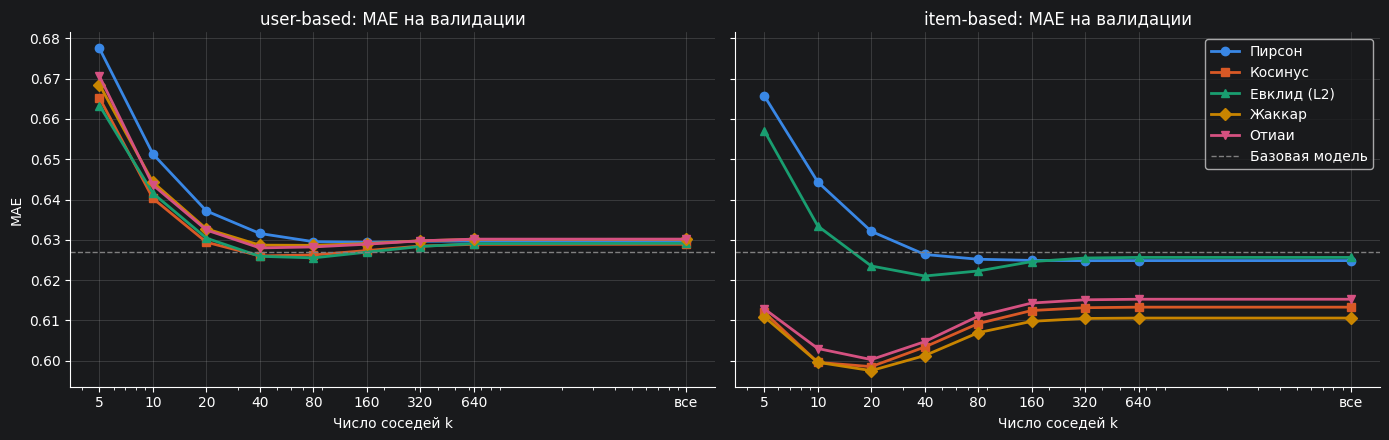

ЛУЧШЕЕ k ДЛЯ ПРОГНОЗА (валидация):
                          k     MAE    RMSE  Покрытие прогноза
Подход     Мера                                               
item-based Евклид (L2)   40  0.6210  0.8420             0.9992
           Жаккар        20  0.5976  0.8127             0.9992
           Косинус       20  0.5985  0.8113             0.9992
           Отиаи         20  0.6003  0.8143             0.9992
           Пирсон       320  0.6248  0.8455             0.9950
user-based Евклид (L2)   80  0.6255  0.8463             0.9992
           Жаккар        80  0.6286  0.8499             0.9992
           Косинус       40  0.6260  0.8466             0.9992
           Отиаи         40  0.6280  0.8494             0.9992
           Пирсон       160  0.6294  0.8537             0.9922


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, approach in zip(axes, PREDICTORS):
    part = pred_tuning[pred_tuning["Подход"] == approach]
    for name in MEASURES:
        line = part[part["Мера"] == name]
        ax.plot(line["k"], line["MAE"], marker=MEASURE_MARKERS[name], color=MEASURE_COLORS[name], label=name)
    baseline_mae = baselines.query("Этап == 'valid' and Метод == 'Смещения mu + b_u + b_i'")["MAE"].iloc[0]
    ax.axhline(baseline_mae, color="gray", linestyle="--", linewidth=1, label="Базовая модель")
    ax.set_xscale("log")
    ax.set_xticks(K_GRID)
    ax.set_xticklabels(k_labels(K_GRID))
    ax.set_title(f"{approach}: MAE на валидации")
    ax.set_xlabel("Число соседей k")
axes[0].set_ylabel("MAE")
axes[1].legend()
plt.tight_layout()
plt.show()

best_pred_k = (pred_tuning.loc[pred_tuning.groupby(["Подход", "Мера"])["MAE"].idxmin()]
               .set_index(["Подход", "Мера"]))
print("ЛУЧШЕЕ k ДЛЯ ПРОГНОЗА (валидация):")
print(best_pred_k.round(4).to_string())

# Топ-N рекомендации

Для списка рекомендаций прогнозировать точную оценку не обязательно — нужно упорядочить фильмы по тому, насколько вероятно, что фильм **понравится**. Поэтому оценка релевантности строится из матрицы «понравилось» $L$ (оценка ≥ 4), то есть по той же логике, по которой измеряется качество.

**User-based:** фильм получает «голоса» от $k$ самых похожих пользователей $N_k(u)$, которым он понравился, взвешенные сходством:
$$\text{score}(u, i) = \sum_{v \in N_k(u)} s(u, v)\, l_{vi}.$$

**Item-based:** каждый понравившийся пользователю фильм $j$ «голосует» за свои $k$ самых похожих фильмов $N_k(j)$:
$$\text{score}(u, i) = \sum_{j:\; l_{uj} = 1} s(i, j)\,[i \in N_k(j)].$$

В матричном виде это просто произведения: $S_k L$ для user-based и $L S_k$ для item-based, где $S_k$ — матрица сходства, в каждой строке которой оставлены только $k$ наибольших положительных значений. Поэтому рекомендации для всех пользователей сразу строятся за доли секунды.

Уже оценённые пользователем фильмы из списка исключаются. Если у пользователя нет ни соседей, ни понравившихся фильмов, все оценки равны нулю, и список заполняется популярными фильмами.

In [20]:
def keep_top_k(S, k):
    # В каждой строке оставляем k наибольших положительных значений сходства
    S = np.where(S > 0, S, 0).astype(np.float32)
    if k >= S.shape[1]:
        return S
    top = np.argpartition(-S, k, axis=1)[:, :k]
    result = np.zeros_like(S)
    rows = np.arange(S.shape[0])[:, None]
    result[rows, top] = S[rows, top]
    return result


def scores_user_based(phase, S, k):
    return keep_top_k(S, k) @ phase["L"].astype(np.float32)


def scores_item_based(phase, S, k, weights=None):
    liked = phase["L"] if weights is None else phase["L"] * weights
    return liked.astype(np.float32) @ keep_top_k(S, k)


SCORERS = {"user-based": scores_user_based, "item-based": scores_item_based}

Подбор $k$ для топ-N рекомендаций на валидационной выборке. Критерий — NDCG@10: он учитывает и то, сколько понравившихся фильмов попало в список, и то, насколько высоко они стоят.

In [21]:
K_GRID_TOPN = [10, 20, 40, 80, 160, 320, 640, ALL_NEIGHBOURS]


@measure_resources
def tune_topn():
    rows = []
    for approach, scorer in SCORERS.items():
        for name, S in sims_fit[approach].items():
            for k in K_GRID_TOPN:
                recs = recommend(scorer(fit, S, k), fit)
                rows.append({"Подход": approach, "Мера": name, "k": k, **evaluate_topn(recs, valid)})
    return pd.DataFrame(rows)


topn_tuning = tune_topn()

Время: 12.77с
Память: +-2.1 MB (макс: 948.0 MB)


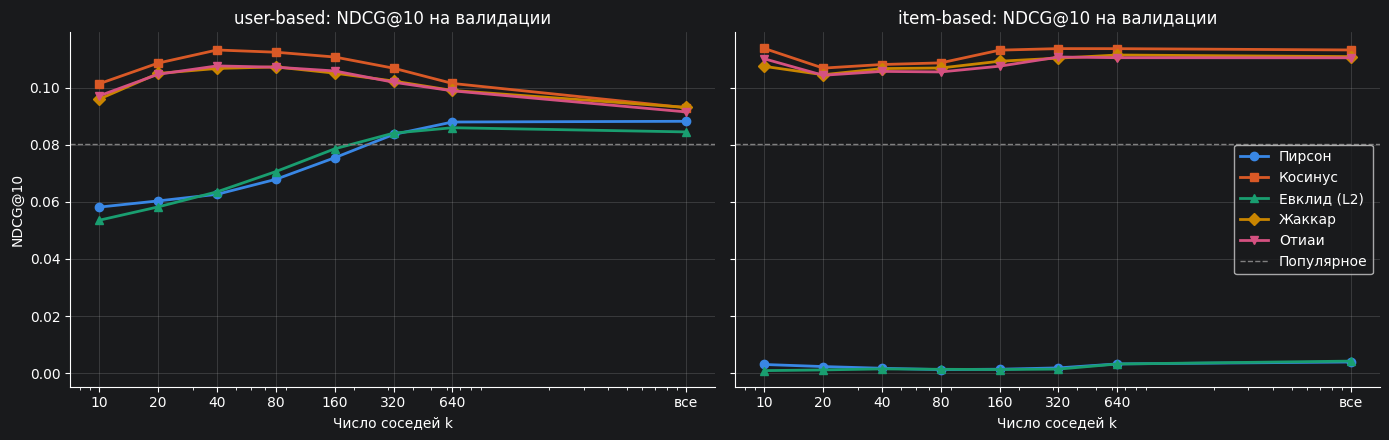

ЛУЧШЕЕ k ДЛЯ ТОП-N (валидация):
                            k  Precision@10  Recall@10  NDCG@10  Покрытие каталога
Подход     Мера                                                                   
item-based Евклид (L2)  10000        0.0035     0.0044   0.0042             0.5915
           Жаккар         640        0.0688     0.1248   0.1115             0.2332
           Косинус         10        0.0727     0.1346   0.1138             0.3026
           Отиаи          320        0.0700     0.1256   0.1108             0.2008
           Пирсон       10000        0.0034     0.0040   0.0039             0.5185
user-based Евклид (L2)    640        0.0555     0.0975   0.0860             0.0434
           Жаккар          80        0.0662     0.1233   0.1073             0.0762
           Косинус         40        0.0712     0.1317   0.1133             0.1050
           Отиаи           40        0.0672     0.1238   0.1077             0.1013
           Пирсон       10000        0.0563     0.1034 

In [22]:
popular_ndcg = baselines.query("Этап == 'valid' and Метод == 'Популярное'")["NDCG@10"].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, approach in zip(axes, SCORERS):
    part = topn_tuning[topn_tuning["Подход"] == approach]
    for name in MEASURES:
        line = part[part["Мера"] == name]
        ax.plot(line["k"], line["NDCG@10"], marker=MEASURE_MARKERS[name], color=MEASURE_COLORS[name], label=name)
    ax.axhline(popular_ndcg, color="gray", linestyle="--", linewidth=1, label="Популярное")
    ax.set_xscale("log")
    ax.set_xticks(K_GRID_TOPN)
    ax.set_xticklabels(k_labels(K_GRID_TOPN))
    ax.set_title(f"{approach}: NDCG@10 на валидации")
    ax.set_xlabel("Число соседей k")
axes[0].set_ylabel("NDCG@10")
axes[1].legend()
plt.tight_layout()
plt.show()

best_topn_k = (topn_tuning.loc[topn_tuning.groupby(["Подход", "Мера"])["NDCG@10"].idxmax()]
               .set_index(["Подход", "Мера"]))
print("ЛУЧШЕЕ k ДЛЯ ТОП-N (валидация):")
print(best_topn_k.round(4).to_string())

Покрытие каталога при лучшем $k$ показывает, насколько разнообразны рекомендации. Метод с хорошим NDCG, но покрытием в несколько процентов, по сути рекомендует всем одни и те же популярные фильмы.

Если меры «по значениям оценок» (Пирсон, Евклид) в топ-N заметно уступают мерам «по факту оценивания», причина обычно в выборе соседей. Пирсон и Евклид считаются только по общим фильмам, поэтому максимальное сходство получают пары с одним-двумя общими фильмами, оценёнными одинаково. В item-based это особенно заметно: ближайшими «соседями» фильма оказываются малоизвестные фильмы, которые оценили один-два тех же зрителя, и рекомендации заполняются такими случайными фильмами (отсюда и высокое покрытие каталога при низкой точности). Косинус, Жаккар и Отиаи нормируются по всем оценкам объекта и такие пары не выделяют. На этом наблюдении основан первый собственный метод ниже.

# Итоговое сравнение на тестовой выборке

Каждая мера проверяется на тесте с тем $k$, который оказался лучшим на валидации (отдельно для прогноза и для топ-N). Матрицы сходства пересчитаны по полной обучающей выборке `train_full`.

In [23]:
u_test, i_test, y_test = eval_pairs(test)
sims_full = {"user-based": user_sims_full, "item-based": item_sims_full}
test_recs = {}   # рекомендации каждого метода на тесте


@measure_resources
def evaluate_on_test():
    rows = []
    for approach in PREDICTORS:
        for name in MEASURES:
            S = sims_full[approach][name]
            k_pred = int(best_pred_k.loc[(approach, name), "k"])
            k_topn = int(best_topn_k.loc[(approach, name), "k"])
            pred = PREDICTORS[approach](full, S, k_pred, u_test, i_test)
            recs = recommend(SCORERS[approach](full, S, k_topn), full)
            test_recs[f"{approach}: {name}"] = recs
            rows.append({"Этап": "test", "Метод": f"{approach}: {name}", "Подход": approach, "Мера": name,
                         "k прогноз": k_pred, "k топ-N": k_topn,
                         **evaluate_prediction(pred, full, u_test, i_test, y_test),
                         **evaluate_topn(recs, test)})
    return rows


results += evaluate_on_test()

Время: 9.44с
Память: +8.8 MB (макс: 959.5 MB)


In [24]:
METRIC_COLUMNS = ["MAE", "RMSE", "Покрытие прогноза", "Precision@10", "Recall@10", "NDCG@10", "Покрытие каталога"]


def results_table(stage="test", approaches=None):
    table = pd.DataFrame(results)
    table = table[table["Этап"] == stage]
    if approaches is not None:
        table = table[table["Подход"].isin(approaches)]
    columns = ["Метод"] + [c for c in ["k прогноз", "k топ-N"] if c in table] + METRIC_COLUMNS
    return table[columns].set_index("Метод")


main_table = results_table("test", ["Базовый", "user-based", "item-based"])
print("ИТОГОВОЕ СРАВНЕНИЕ НА ТЕСТЕ:")
print(main_table.round(4).to_string())

ИТОГОВОЕ СРАВНЕНИЕ НА ТЕСТЕ:
                         k прогноз  k топ-N     MAE    RMSE  Покрытие прогноза  Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                                                                              
Глобальное среднее             NaN      NaN  0.7896  1.0409             1.0000           NaN        NaN      NaN                NaN
Среднее пользователя           NaN      NaN  0.6680  0.8976             1.0000           NaN        NaN      NaN                NaN
Среднее фильма                 NaN      NaN  0.7422  0.9843             1.0000           NaN        NaN      NaN                NaN
Смещения mu + b_u + b_i        NaN      NaN  0.6188  0.8336             1.0000           NaN        NaN      NaN                NaN
Популярное                     NaN      NaN     NaN     NaN                NaN        0.0647     0.0886   0.0937             0.0447
Случайное                      NaN      NaN    

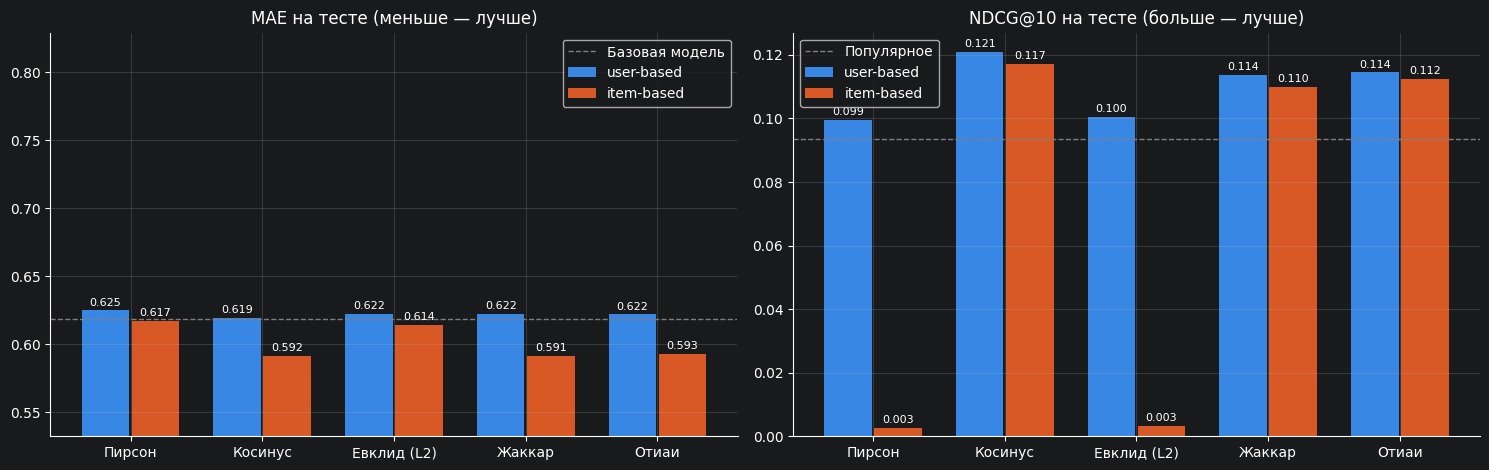

In [25]:
measure_part = main_table.loc[[f"{a}: {m}" for a in PREDICTORS for m in MEASURES]]
labels = list(MEASURES)
x = np.arange(len(labels))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, metric, reference, ref_label in [
    (axes[0], "MAE", "Смещения mu + b_u + b_i", "Базовая модель"),
    (axes[1], "NDCG@10", "Популярное", "Популярное"),
]:
    for shift, approach, color in [(-width / 2, "user-based", PALETTE[0]), (width / 2, "item-based", PALETTE[1])]:
        values = [measure_part.loc[f"{approach}: {m}", metric] for m in labels]
        bars = ax.bar(x + shift, values, width=width * 0.95, color=color, label=approach)
        ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
    ax.axhline(main_table.loc[reference, metric], color="gray", linestyle="--", linewidth=1, label=ref_label)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_title(f"{metric} на тесте" + (" (меньше — лучше)" if metric == "MAE" else " (больше — лучше)"))
    ax.legend()
axes[0].set_ylim(main_table["MAE"].min() * 0.9, main_table["MAE"].max() * 1.05)
plt.tight_layout()
plt.show()

In [26]:
best_pred_method = measure_part["MAE"].idxmin()
best_topn_method = measure_part["NDCG@10"].idxmax()
best_user = measure_part.loc[[f"user-based: {m}" for m in MEASURES], "NDCG@10"].idxmax()
best_item = measure_part.loc[[f"item-based: {m}" for m in MEASURES], "NDCG@10"].idxmax()

print(f"Лучший метод для прогноза оценки: {best_pred_method} "
      f"(MAE {measure_part.loc[best_pred_method, 'MAE']:.4f})")
print(f"Лучший метод для топ-N:           {best_topn_method} "
      f"(NDCG@10 {measure_part.loc[best_topn_method, 'NDCG@10']:.4f})")
print(f"Лучший user-based для топ-N:      {best_user}")
print(f"Лучший item-based для топ-N:      {best_item}")

Лучший метод для прогноза оценки: item-based: Жаккар (MAE 0.5915)
Лучший метод для топ-N:           user-based: Косинус (NDCG@10 0.1210)
Лучший user-based для топ-N:      user-based: Косинус
Лучший item-based для топ-N:      item-based: Косинус


# Дополнительно: гибридная система

Простейшая гибридная система объединяет user-based и item-based методы. Методичка предлагает три вида аналитики:
- **суперпозиция** — наложение результатов двух методов: взвешенная сумма их оценок;
- **контрапозиция** — сопоставление различий: какие фильмы рекомендует только один из методов и насколько удачны такие рекомендации;
- **поиск общих закономерностей** — что общего у рекомендаций обоих методов, и как это использовать для повышения релевантности.

Для гибрида берутся лучшие на валидации варианты каждого подхода (мера и $k$ по NDCG@10).

In [27]:
def best_config(approach):
    part = best_topn_k.loc[approach]
    measure = part["NDCG@10"].idxmax()
    return measure, int(part.loc[measure, "k"])


user_measure, user_k = best_config("user-based")
item_measure, item_k = best_config("item-based")
print(f"user-based: {user_measure}, k = {user_k}")
print(f"item-based: {item_measure}, k = {item_k}")


def normalize_rows(scores):
    # Оценки двух методов в разных масштабах; делим на максимум в строке, чтобы привести к [0, 1]
    top = scores.max(axis=1, keepdims=True)
    return np.divide(scores, top, out=np.zeros_like(scores), where=top > 0)


def hybrid_parts(phase, user_sims, item_sims):
    U = normalize_rows(scores_user_based(phase, user_sims[user_measure], user_k))
    I = normalize_rows(scores_item_based(phase, item_sims[item_measure], item_k))
    return U, I


U_fit, I_fit = hybrid_parts(fit, user_sims_fit, item_sims_fit)
U_full, I_full = hybrid_parts(full, user_sims_full, item_sims_full)

user-based: Косинус, k = 40
item-based: Косинус, k = 10


Суперпозиция

Итоговая оценка релевантности — взвешенная сумма нормированных оценок двух методов:
$$\text{score}(u,i) = \alpha \cdot \text{score}_{user}(u,i) + (1 - \alpha) \cdot \text{score}_{item}(u,i).$$
При $\alpha = 1$ получается чистый user-based, при $\alpha = 0$ — чистый item-based. Вес $\alpha$ подбирается на валидации. Аналогично строится гибридный прогноз оценки: $\hat r = \alpha\, \hat r_{user} + (1 - \alpha)\, \hat r_{item}$.

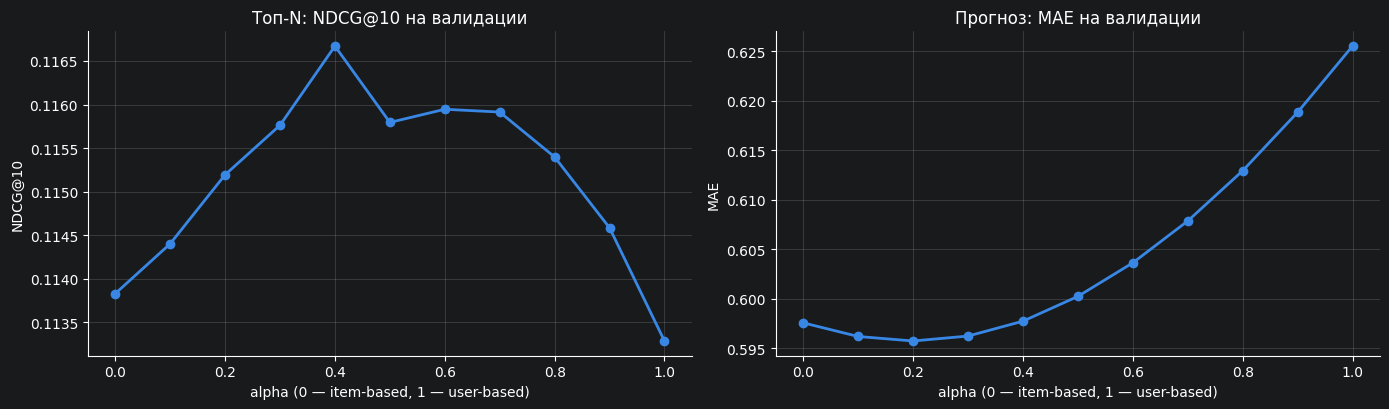

Лучший alpha для топ-N: 0.4, для прогноза: 0.2


In [28]:
ALPHAS = np.round(np.linspace(0, 1, 11), 1)

alpha_rows = []
for alpha in ALPHAS:
    recs = recommend(alpha * U_fit + (1 - alpha) * I_fit, fit)
    alpha_rows.append({"alpha": alpha, **evaluate_topn(recs, valid)})
alpha_topn = pd.DataFrame(alpha_rows)

# Прогноз оценок: лучшие меры и k для прогноза в каждом подходе
pred_user_measure = best_pred_k.loc["user-based", "MAE"].idxmin()
pred_item_measure = best_pred_k.loc["item-based", "MAE"].idxmin()
pred_user_k = int(best_pred_k.loc[("user-based", pred_user_measure), "k"])
pred_item_k = int(best_pred_k.loc[("item-based", pred_item_measure), "k"])


def hybrid_predictions(phase, user_sims, item_sims, u_idx, i_idx):
    base = baseline_prediction(phase, u_idx, i_idx)
    pu = predict_user_based(phase, user_sims[pred_user_measure], pred_user_k, u_idx, i_idx)
    pi = predict_item_based(phase, item_sims[pred_item_measure], pred_item_k, u_idx, i_idx)
    return np.where(np.isfinite(pu), pu, base), np.where(np.isfinite(pi), pi, base)


pu_val, pi_val = hybrid_predictions(fit, user_sims_fit, item_sims_fit, u_val, i_val)
alpha_pred = pd.DataFrame([
    {"alpha": a, **evaluate_prediction(a * pu_val + (1 - a) * pi_val, fit, u_val, i_val, y_val)}
    for a in ALPHAS
])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(alpha_topn["alpha"], alpha_topn["NDCG@10"], marker="o", color=MAIN_COLOR)
axes[0].set_title("Топ-N: NDCG@10 на валидации")
axes[0].set_xlabel("alpha (0 — item-based, 1 — user-based)")
axes[0].set_ylabel("NDCG@10")
axes[1].plot(alpha_pred["alpha"], alpha_pred["MAE"], marker="o", color=MAIN_COLOR)
axes[1].set_title("Прогноз: MAE на валидации")
axes[1].set_xlabel("alpha (0 — item-based, 1 — user-based)")
axes[1].set_ylabel("MAE")
plt.tight_layout()
plt.show()

best_alpha_topn = alpha_topn.loc[alpha_topn["NDCG@10"].idxmax(), "alpha"]
best_alpha_pred = alpha_pred.loc[alpha_pred["MAE"].idxmin(), "alpha"]
print(f"Лучший alpha для топ-N: {best_alpha_topn}, для прогноза: {best_alpha_pred}")

Если лучшее $\alpha$ лежит строго между 0 и 1, методы **дополняют** друг друга: каждый находит то, что пропускает другой. Если лучшее $\alpha$ на краю, один из методов просто сильнее, и смешивание не помогает.

Контрапозиция

Сравним списки рекомендаций двух методов на валидации для каждого пользователя. Фильмы делятся на три группы: рекомендованные **обоими** методами, **только user-based** и **только item-based**. Для каждой группы считается точность — доля фильмов, которые пользователь потом оценил не ниже 4.

           Группа  Фильмов  Попаданий  Точность
       Оба метода    11300        871    0.0771
Только user-based     8580        458    0.0534
Только item-based     8580        486    0.0566

Средняя доля общих фильмов в двух списках: 56.8%


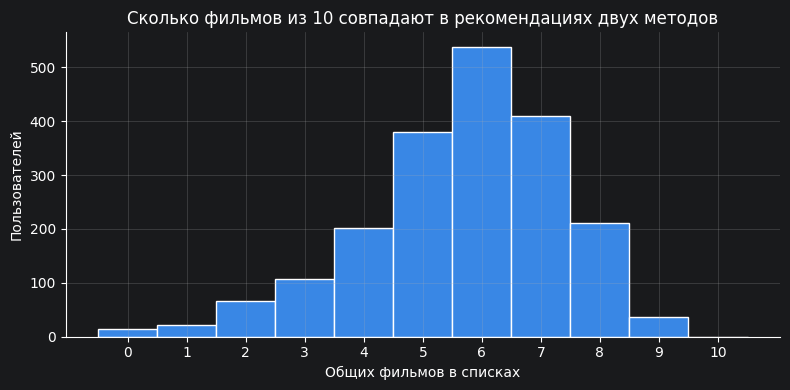

In [29]:
def contraposition(recs_a, recs_b, eval_df, name_a, name_b):
    relevant = (eval_df[eval_df["rating"] >= mc.RELEVANCE_THRESHOLD]
                .groupby("userId")["movieId"].apply(set).to_dict())
    counts = {"both": [0, 0], "only_a": [0, 0], "only_b": [0, 0]}   # [фильмов, попаданий]
    overlaps = []
    for user in eval_df["userId"].unique():
        a, b = set(recs_a[user]), set(recs_b[user])
        rel = relevant.get(user, set())
        overlaps.append(len(a & b) / TOP_N)
        for group, items in [("both", a & b), ("only_a", a - b), ("only_b", b - a)]:
            counts[group][0] += len(items)
            counts[group][1] += len(items & rel)
    table = pd.DataFrame({
        "Группа": [f"Оба метода", f"Только {name_a}", f"Только {name_b}"],
        "Фильмов": [counts[g][0] for g in counts],
        "Попаданий": [counts[g][1] for g in counts],
    })
    table["Точность"] = table["Попаданий"] / table["Фильмов"].clip(lower=1)
    return table, np.array(overlaps)


recs_user_fit = recommend(U_fit, fit)
recs_item_fit = recommend(I_fit, fit)
contra, overlaps = contraposition(recs_user_fit, recs_item_fit, valid, "user-based", "item-based")
print(contra.round(4).to_string(index=False))
print(f"\nСредняя доля общих фильмов в двух списках: {overlaps.mean():.1%}")

plt.figure(figsize=(8, 4))
plt.hist(overlaps * TOP_N, bins=np.arange(-0.5, TOP_N + 1.5), color=MAIN_COLOR, edgecolor="white")
plt.title("Сколько фильмов из 10 совпадают в рекомендациях двух методов")
plt.xlabel("Общих фильмов в списках")
plt.ylabel("Пользователей")
plt.xticks(range(TOP_N + 1))
plt.tight_layout()
plt.show()

Общие закономерности: консенсус методов

Если точность в группе «оба метода» заметно выше, чем в группах «только один метод», то **согласие двух независимых методов — признак надёжной рекомендации**. Эту закономерность можно использовать напрямую: поднимать в списке фильмы, которые высоко ставят оба метода.

Для этого используется слияние рангов (Reciprocal Rank Fusion, RRF): каждый метод вносит вклад $\frac{1}{c + \text{ранг}}$, где ранг — позиция фильма в его списке:
$$\text{score}(u,i) = \frac{1}{c + \text{rank}_{user}(u,i)} + \frac{1}{c + \text{rank}_{item}(u,i)}, \quad c = 60.$$
Фильм, который оба метода ставят высоко, получает большой суммарный вклад. Фильм из начала списка только одного метода — вклад поменьше. В отличие от суперпозиции, RRF работает с рангами, а не с оценками, поэтому не зависит от масштаба оценок методов.

In [30]:
RRF_C = 60


def ranks_by_row(scores, phase):
    scores = np.where(phase["M"] > 0, -np.inf, scores)
    order = np.argsort(-scores, axis=1)
    ranks = np.empty_like(order)
    rows = np.arange(scores.shape[0])[:, None]
    ranks[rows, order] = np.arange(1, scores.shape[1] + 1)
    return ranks


def rrf_scores(phase, U, I):
    return 1 / (RRF_C + ranks_by_row(U, phase)) + 1 / (RRF_C + ranks_by_row(I, phase))


rrf_val = evaluate_topn(recommend(rrf_scores(fit, U_fit, I_fit), fit), valid)
print("RRF на валидации:", {k: round(v, 4) for k, v in rrf_val.items()})
print("Суперпозиция на валидации:",
      {k: round(v, 4) for k, v in alpha_topn.loc[alpha_topn['alpha'] == best_alpha_topn].iloc[0].items()})

RRF на валидации: {'Precision@10': 0.0737, 'Recall@10': 0.1364, 'NDCG@10': 0.1176, 'Покрытие каталога': 0.1547}
Суперпозиция на валидации: {'alpha': 0.4, 'Precision@10': 0.074, 'Recall@10': 0.1362, 'NDCG@10': 0.1167, 'Покрытие каталога': 0.1972}


Проверка гибридов на тестовой выборке

In [31]:
pu_test, pi_test = hybrid_predictions(full, user_sims_full, item_sims_full, u_test, i_test)
hybrid_pred = best_alpha_pred * pu_test + (1 - best_alpha_pred) * pi_test

test_recs["Гибрид: суперпозиция"] = recommend(best_alpha_topn * U_full + (1 - best_alpha_topn) * I_full, full)
test_recs["Гибрид: RRF"] = recommend(rrf_scores(full, U_full, I_full), full)

results.append({"Этап": "test", "Метод": "Гибрид: суперпозиция", "Подход": "Гибрид",
                **evaluate_prediction(hybrid_pred, full, u_test, i_test, y_test),
                **evaluate_topn(test_recs["Гибрид: суперпозиция"], test)})
results.append({"Этап": "test", "Метод": "Гибрид: RRF", "Подход": "Гибрид",
                **evaluate_topn(test_recs["Гибрид: RRF"], test)})

contra_test, overlaps_test = contraposition(test_recs[f"user-based: {user_measure}"],
                                            test_recs[f"item-based: {item_measure}"], test,
                                            "user-based", "item-based")
print("КОНТРАПОЗИЦИЯ НА ТЕСТЕ:")
print(contra_test.round(4).to_string(index=False))
print()
print(results_table("test").loc[[f"user-based: {user_measure}", f"item-based: {item_measure}",
                                 "Гибрид: суперпозиция", "Гибрид: RRF"]].round(4).to_string())

КОНТРАПОЗИЦИЯ НА ТЕСТЕ:
           Группа  Фильмов  Попаданий  Точность
       Оба метода    11047       1058    0.0958
Только user-based     8833        522    0.0591
Только item-based     8833        521    0.0590

                      k прогноз  k топ-N     MAE    RMSE  Покрытие прогноза  Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                                                                           
user-based: Косинус        40.0     40.0  0.6194  0.8376             0.9994        0.0823     0.1206   0.1210             0.1109
item-based: Косинус        20.0     10.0  0.5916  0.8034             0.9994        0.0822     0.1174   0.1172             0.2839
Гибрид: суперпозиция        NaN      NaN  0.5902  0.8033             1.0000        0.0837     0.1201   0.1203             0.1876
Гибрид: RRF                 NaN      NaN     NaN     NaN                NaN        0.0844     0.1204   0.1206             0.1538


# Дополнительно: собственные методы

Собственные методы построены на наблюдениях, сделанных выше и в ноутбуке подготовки данных.

**Метод 1. Мера «Пирсон × Жаккар»** — собственная мера сходства:
$$s(u,v) = \max(\text{Пирсон}(u,v),\, 0) \cdot \text{Жаккар}(u,v).$$
Идея: у Пирсона и Жаккара противоположные сильные и слабые стороны. Пирсон видит **согласие оценок**, но ненадёжен при малом числе общих фильмов. Жаккар видит **объём общего опыта**, но не различает совпадение и противоположность вкусов. Произведение высоко, только когда зрители и смотрят одно и то же, и оценивают одинаково. Множитель Жаккара работает как «штраф за ненадёжность»: пара с двумя общими фильмами не станет лучшими соседями, даже если корреляция по ним равна 1.

**Метод 2. Item-based с учётом свежести вкуса** — эвристика на основе анализа сессий:
$$\text{score}(u,i) = \sum_{j:\; l_{uj}=1} w_{uj}\, s(i,j)\,[i \in N_k(j)], \qquad w_{uj} = 0.5^{\,b_{uj} / h}.$$
Здесь $b_{uj}$ — сколько сессий назад пользователь оценил фильм $j$ (0 — в последней сессии), $h$ — «период полураспада»: через $h$ сессий вес понравившегося фильма уменьшается вдвое. Идея: при временном разбиении нужно угадать **следующие** оценки, а интересы зрителя со временем меняются, поэтому недавно понравившиеся фильмы лучше описывают текущий вкус. В ноутбуке 00 было показано, что оценки выставляются пачками, поэтому «давность» измеряется в сессиях, а не в отдельных оценках. У пользователей с единственной сессией все веса равны 1, и метод совпадает с обычным item-based.

In [32]:
def sim_pearson_jaccard(R, M):
    return (np.clip(sim_pearson(R, M), 0, None) * sim_jaccard(R, M)).astype(np.float32)


own_sims = {}
for phase_name, phase in [("fit", fit), ("full", full)]:
    own_sims[(phase_name, "user-based")] = sim_pearson_jaccard(phase["R"], phase["M"])
    own_sims[(phase_name, "item-based")] = sim_pearson_jaccard(phase["R"].T, phase["M"].T)

# Подбор k для собственной меры на валидации
own_rows = []
for approach in PREDICTORS:
    S = own_sims[("fit", approach)]
    for k in K_GRID_TOPN:
        recs = recommend(SCORERS[approach](fit, S, k), fit)
        own_rows.append({"Подход": approach, "k": k, "Задача": "топ-N", **evaluate_topn(recs, valid)})
    for k in K_GRID:
        pred = PREDICTORS[approach](fit, S, k, u_val, i_val)
        own_rows.append({"Подход": approach, "k": k, "Задача": "прогноз",
                         **evaluate_prediction(pred, fit, u_val, i_val, y_val)})
own_tuning = pd.DataFrame(own_rows)

own_best = {}
for approach in PREDICTORS:
    part = own_tuning[own_tuning["Подход"] == approach]
    topn_part, pred_part = part[part["Задача"] == "топ-N"], part[part["Задача"] == "прогноз"]
    own_best[approach] = (int(pred_part.loc[pred_part["MAE"].idxmin(), "k"]),
                          int(topn_part.loc[topn_part["NDCG@10"].idxmax(), "k"]))
    print(f"Пирсон × Жаккар, {approach}: k прогноз = {own_best[approach][0]}, k топ-N = {own_best[approach][1]}, "
          f"MAE = {pred_part['MAE'].min():.4f}, NDCG@10 = {topn_part['NDCG@10'].max():.4f}")

Пирсон × Жаккар, user-based: k прогноз = 40, k топ-N = 40, MAE = 0.6232, NDCG@10 = 0.1055
Пирсон × Жаккар, item-based: k прогноз = 20, k топ-N = 10, MAE = 0.5990, NDCG@10 = 0.1021


In [33]:
HALF_LIVES = [0.5, 1, 2, 4, 8, np.inf]
item_S_fit = item_sims_fit[item_measure]

recency_rows = []
for h in HALF_LIVES:
    weights = np.ones_like(fit["B"]) if np.isinf(h) else 0.5 ** (fit["B"] / h)
    recs = recommend(scores_item_based(fit, item_S_fit, item_k, weights), fit)
    recency_rows.append({"h": h, **evaluate_topn(recs, valid)})
recency_tuning = pd.DataFrame(recency_rows)
print(f"Item-based со свежестью вкуса (мера {item_measure}, k = {item_k}), валидация:")
print(recency_tuning.round(4).to_string(index=False))
print("(h = inf — без учёта свежести, обычный item-based)")

finite = recency_tuning[np.isfinite(recency_tuning["h"])]
best_h = finite.loc[finite["NDCG@10"].idxmax(), "h"]
print(f"\nЛучший период полураспада: h = {best_h} сессий")

Item-based со свежестью вкуса (мера Косинус, k = 10), валидация:
  h  Precision@10  Recall@10  NDCG@10  Покрытие каталога
0.5        0.0713     0.1322   0.1139             0.5988
1.0        0.0735     0.1364   0.1172             0.5691
2.0        0.0741     0.1377   0.1182             0.4952
4.0        0.0748     0.1384   0.1181             0.4414
8.0        0.0749     0.1382   0.1169             0.3829
inf        0.0727     0.1346   0.1138             0.3026
(h = inf — без учёта свежести, обычный item-based)

Лучший период полураспада: h = 2.0 сессий


Проверка собственных методов на тестовой выборке

In [34]:
for approach in PREDICTORS:
    S = own_sims[("full", approach)]
    k_pred, k_topn = own_best[approach]
    name = f"Своё: Пирсон × Жаккар ({approach})"
    pred = PREDICTORS[approach](full, S, k_pred, u_test, i_test)
    test_recs[name] = recommend(SCORERS[approach](full, S, k_topn), full)
    results.append({"Этап": "test", "Метод": name, "Подход": "Своё", "k прогноз": k_pred, "k топ-N": k_topn,
                    **evaluate_prediction(pred, full, u_test, i_test, y_test),
                    **evaluate_topn(test_recs[name], test)})

recency_weights = 0.5 ** (full["B"] / best_h)
name = f"Своё: item-based со свежестью (h={best_h})"
test_recs[name] = recommend(scores_item_based(full, item_sims_full[item_measure], item_k, recency_weights), full)
results.append({"Этап": "test", "Метод": name, "Подход": "Своё", "k топ-N": item_k,
                **evaluate_topn(test_recs[name], test)})

print("СОБСТВЕННЫЕ МЕТОДЫ В СРАВНЕНИИ С ЛУЧШИМИ МАТЕМАТИЧЕСКИМИ (тест):")
compare_names = [best_pred_method, best_topn_method, f"user-based: {user_measure}", f"item-based: {item_measure}"]
own_table = results_table("test")
own_table = own_table.loc[list(dict.fromkeys(compare_names)) + list(own_table.index[own_table.index.str.startswith("Своё")])]
print(own_table.round(4).to_string())

СОБСТВЕННЫЕ МЕТОДЫ В СРАВНЕНИИ С ЛУЧШИМИ МАТЕМАТИЧЕСКИМИ (тест):
                                       k прогноз  k топ-N     MAE    RMSE  Покрытие прогноза  Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                                                                                            
item-based: Жаккар                          20.0    640.0  0.5915  0.8057             0.9994        0.0761     0.1105   0.1100             0.2054
user-based: Косинус                         40.0     40.0  0.6194  0.8376             0.9994        0.0823     0.1206   0.1210             0.1109
item-based: Косинус                         20.0     10.0  0.5916  0.8034             0.9994        0.0822     0.1174   0.1172             0.2839
Своё: Пирсон × Жаккар (user-based)          40.0     40.0  0.6179  0.8369             0.9938        0.0788     0.1114   0.1129             0.0931
Своё: Пирсон × Жаккар (item-based)          20.0     10.0  

# Дополнительно: сравнение с отзывами пользователей

Предлагается сравнить рекомендации с **отзывами пользователей** на них. В наших данных роль отзыва играют тестовые оценки: это то, что пользователь посмотрел и оценил **после** момента, когда система построила рекомендации.

Для каждого метода по 10 рекомендациям каждого пользователя считается:
- **доля отреагировавших** — сколько рекомендованных фильмов пользователь потом действительно оценил (заметил и посмотрел);
- **средняя оценка отклика** — как он их оценил;
- **доля положительных откликов** — сколько из оценённых получили 4 и выше.

Для сравнения — средняя оценка всех тестовых оценок: рекомендации полезны, если фильмы из них оцениваются выше, чем то, что пользователь смотрит сам по себе.

In [35]:
test_lookup = test.set_index(["userId", "movieId"])["rating"]
test_users = test["userId"].unique()


def feedback(recs, n=TOP_N):
    pairs = pd.MultiIndex.from_tuples([(u, m) for u in test_users for m in recs[u][:n]])
    responses = test_lookup.reindex(pairs)
    rated = responses.dropna()
    return {
        "Доля отреагировавших": responses.notna().mean(),
        "Средняя оценка отклика": rated.mean(),
        "Доля положительных откликов": (rated >= mc.RELEVANCE_THRESHOLD).mean(),
        "Откликов": len(rated),
    }


test_recs["Популярное"] = recommend(np.tile(full["popularity"], (n_users, 1)), full)
feedback_names = ["Популярное", f"user-based: {user_measure}", f"item-based: {item_measure}",
                  "Гибрид: суперпозиция", "Гибрид: RRF"] + [n for n in test_recs if n.startswith("Своё")]
feedback_table = pd.DataFrame({name: feedback(test_recs[name]) for name in feedback_names}).T
print(f"Средняя оценка всех тестовых оценок: {test['rating'].mean():.3f}, "
      f"доля >= {mc.RELEVANCE_THRESHOLD}: {(test['rating'] >= mc.RELEVANCE_THRESHOLD).mean():.1%}\n")
print(feedback_table.round(4).to_string())

Средняя оценка всех тестовых оценок: 3.463, доля >= 4.0: 44.7%

                                       Доля отреагировавших  Средняя оценка отклика  Доля положительных откликов  Откликов
Популярное                                           0.0976                  3.8562                       0.6407    1940.0
user-based: Косинус                                  0.1254                  3.8770                       0.6340    2492.0
item-based: Косинус                                  0.1240                  3.8951                       0.6406    2465.0
Гибрид: суперпозиция                                 0.1269                  3.8921                       0.6372    2522.0
Гибрид: RRF                                          0.1277                  3.8939                       0.6384    2539.0
Своё: Пирсон × Жаккар (user-based)                   0.1164                  3.8969                       0.6538    2314.0
Своё: Пирсон × Жаккар (item-based)                   0.1173                

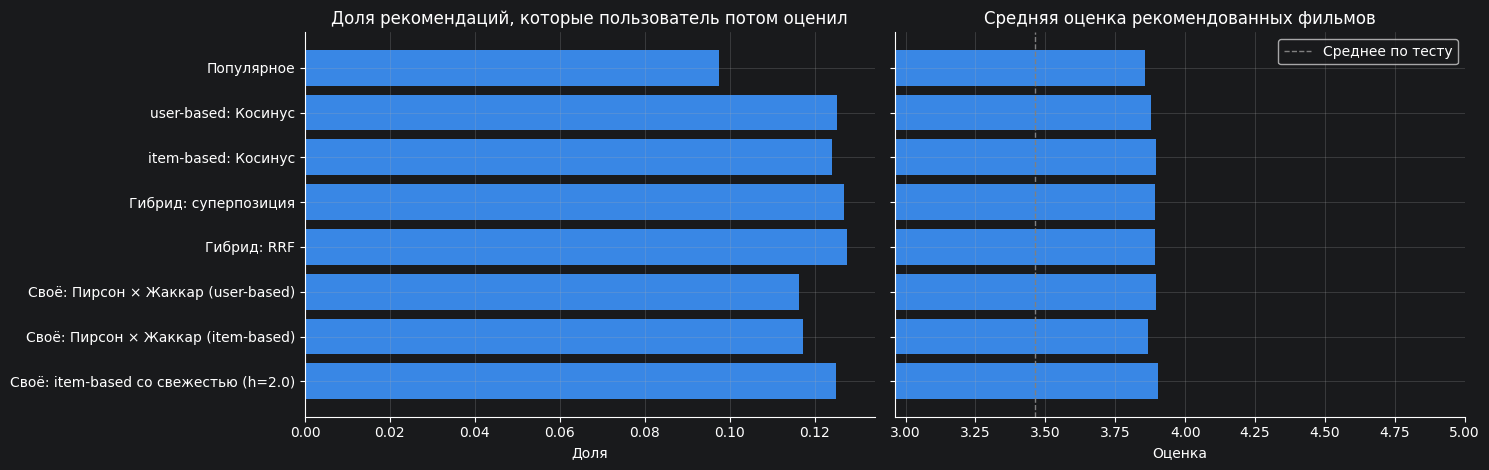

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
names = feedback_table.index
y = np.arange(len(names))

axes[0].barh(y, feedback_table["Доля отреагировавших"], color=MAIN_COLOR)
axes[0].set_yticks(y)
axes[0].set_yticklabels(names)
axes[0].invert_yaxis()
axes[0].set_title("Доля рекомендаций, которые пользователь потом оценил")
axes[0].set_xlabel("Доля")

axes[1].barh(y, feedback_table["Средняя оценка отклика"], color=MAIN_COLOR)
axes[1].axvline(test["rating"].mean(), color="gray", linestyle="--", linewidth=1, label="Среднее по тесту")
axes[1].set_yticks(y)
axes[1].set_yticklabels([])
axes[1].invert_yaxis()
axes[1].set_xlim(test["rating"].mean() - 0.5, 5)
axes[1].set_title("Средняя оценка рекомендованных фильмов")
axes[1].set_xlabel("Оценка")
axes[1].legend()
plt.tight_layout()
plt.show()

Корректировка по отзывам: выбор метода для каждого пользователя

Примечание 2 говорит, что отзывы можно использовать для **смены рекомендательного метода**: выбрать тот, что ближе к реакции пользователя. Реализуем это буквально. Для каждого пользователя по его отзывам на **валидационном** этапе (NDCG@10 на `valid`) выбирается метод, который сработал для него лучше всего. Затем на тесте этот пользователь получает рекомендации выбранного метода. Пользователям без понравившихся фильмов в валидации назначается метод, лучший в среднем.

Кандидаты — популярное, лучший user-based, лучший item-based и суперпозиция.

In [37]:
def per_user_ndcg(recs, eval_df, n=TOP_N):
    relevant = (eval_df[eval_df["rating"] >= mc.RELEVANCE_THRESHOLD]
                .groupby("userId")["movieId"].apply(set))
    discounts = 1 / np.log2(np.arange(2, n + 2))
    values = {}
    for user, rel in relevant.items():
        hits = np.array([m in rel for m in recs[user][:n]], dtype=float)
        values[user] = (hits * discounts).sum() / discounts[:min(len(rel), n)].sum()
    return pd.Series(values)


candidates_val = {
    "Популярное": recommend(np.tile(fit["popularity"], (n_users, 1)), fit),
    "user-based": recs_user_fit,
    "item-based": recs_item_fit,
    "Суперпозиция": recommend(best_alpha_topn * U_fit + (1 - best_alpha_topn) * I_fit, fit),
}
candidates_test = {
    "Популярное": test_recs["Популярное"],
    "user-based": test_recs[f"user-based: {user_measure}"],
    "item-based": test_recs[f"item-based: {item_measure}"],
    "Суперпозиция": test_recs["Гибрид: суперпозиция"],
}

val_ndcg = pd.DataFrame({name: per_user_ndcg(recs, valid) for name, recs in candidates_val.items()})
global_best = val_ndcg.mean().idxmax()
chosen = val_ndcg.idxmax(axis=1)
# при равенстве (например, все нули) остаётся метод, лучший в среднем
chosen[val_ndcg.max(axis=1) == val_ndcg[global_best]] = global_best

adaptive_recs = {}
for user in user_ids:
    method = chosen.get(user, global_best)
    adaptive_recs[user] = candidates_test[method][user]
test_recs["Своё: выбор метода по отзывам"] = adaptive_recs

print("Какой метод выбран пользователям:")
print(chosen.reindex(user_ids).fillna(global_best).value_counts(normalize=True).round(3).to_string())

results.append({"Этап": "test", "Метод": "Своё: выбор метода по отзывам", "Подход": "Своё",
                **evaluate_topn(adaptive_recs, test)})
print()
print(results_table("test").loc[["Популярное", f"user-based: {user_measure}", f"item-based: {item_measure}",
                                 "Гибрид: суперпозиция", "Своё: выбор метода по отзывам"],
                                ["Precision@10", "Recall@10", "NDCG@10", "Покрытие каталога"]].round(4).to_string())

Какой метод выбран пользователям:
Суперпозиция    0.617
user-based      0.141
item-based      0.127
Популярное      0.115

                               Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                             
Популярное                           0.0647     0.0886   0.0937             0.0447
user-based: Косинус                  0.0823     0.1206   0.1210             0.1109
item-based: Косинус                  0.0822     0.1174   0.1172             0.2839
Гибрид: суперпозиция                 0.0837     0.1201   0.1203             0.1876
Своё: выбор метода по отзывам        0.0833     0.1195   0.1209             0.2049


Если адаптивный выбор не лучше лучшего отдельного метода, это тоже результат: для большинства пользователей в валидации всего несколько понравившихся фильмов, и выбор по ним во многом случаен. Тогда надёжнее один общий метод, выбранный по среднему качеству.

# Пример рекомендаций для одного пользователя

Метрики показывают среднее качество, но полезно посмотреть на рекомендации глазами пользователя: похожи ли рекомендованные фильмы на то, что ему нравилось.

In [38]:
example_user = (test[test["rating"] >= mc.RELEVANCE_THRESHOLD]["userId"].value_counts()
                .loc[lambda s: s.between(5, 15)].index[0])
movie_info = movies.set_index("movieId")
u = user_index.get_loc(example_user)

liked = train_full[(train_full["userId"] == example_user) & (train_full["rating"] >= 4.5)]
liked = liked.sort_values("timestamp", ascending=False).head(10)
print(f"Пользователь {example_user}: оценок в train {int(full['M'][u].sum())}, "
      f"средняя оценка {full['user_mean'][u]:.2f}")
print("\nНедавно понравившиеся фильмы (оценка >= 4.5):")
for _, row in liked.iterrows():
    info = movie_info.loc[row["movieId"]]
    print(f"  {row['rating']:.1f}  {info['title']}  [{', '.join(info['genre_list'])}]")

user_test = test_lookup.loc[example_user]
for name in [f"user-based: {user_measure}", f"item-based: {item_measure}", "Гибрид: суперпозиция"]:
    print(f"\nРекомендации — {name}:")
    for movie_id in test_recs[name][example_user]:
        info = movie_info.loc[movie_id]
        response = f"оценил потом на {user_test[movie_id]:.1f}" if movie_id in user_test.index else ""
        print(f"  {info['title']}  [{', '.join(info['genre_list'])}]  {response}")

Пользователь 3601: оценок в train 160, средняя оценка 3.69

Недавно понравившиеся фильмы (оценка >= 4.5):
  4.5  Baby Driver (2017)  [Action, Crime, Thriller]
  5.0  The Revenant (2015)  [Adventure, Drama]
  4.5  Don Jon (2013)  [Comedy, Drama, Romance]
  4.5  12 Years a Slave (2013)  [Drama]
  5.0  American Hustle (2013)  [Crime, Drama]
  4.5  Easy A (2010)  [Comedy, Romance]
  4.5  Crazy, Stupid, Love. (2011)  [Comedy, Drama, Romance]
  4.5  The Nice Guys (2016)  [Crime, Mystery, Thriller]
  5.0  Passengers (2016)  [Adventure, Drama, Romance, Sci-Fi]
  4.5  Hitman's Wife's Bodyguard (2021)  [Action, Comedy, Thriller]

Рекомендации — user-based: Косинус:
  Arrival (2016)  [Sci-Fi]  
  Logan (2017)  [Action, Sci-Fi]  
  Ex Machina (2015)  [Drama, Sci-Fi, Thriller]  
  Guardians of the Galaxy (2014)  [Action, Adventure, Sci-Fi]  оценил потом на 1.0
  The Imitation Game (2014)  [Drama, Thriller, War]  оценил потом на 5.0
  Nightcrawler (2014)  [Crime, Drama, Thriller]  
  Prisoners (2013

# Сводная таблица результатов

In [39]:
summary = results_table("test")
summary.round(4).to_csv("work1_results.csv")
print(summary.round(4).to_string())

                                       k прогноз  k топ-N     MAE    RMSE  Покрытие прогноза  Precision@10  Recall@10  NDCG@10  Покрытие каталога
Метод                                                                                                                                            
Глобальное среднее                           NaN      NaN  0.7896  1.0409             1.0000           NaN        NaN      NaN                NaN
Среднее пользователя                         NaN      NaN  0.6680  0.8976             1.0000           NaN        NaN      NaN                NaN
Среднее фильма                               NaN      NaN  0.7422  0.9843             1.0000           NaN        NaN      NaN                NaN
Смещения mu + b_u + b_i                      NaN      NaN  0.6188  0.8336             1.0000           NaN        NaN      NaN                NaN
Популярное                                   NaN      NaN     NaN     NaN                NaN        0.0647     0.0886   0.09

# Проверка на новом пользователе

Все результаты выше получены для пользователей, чья история уже есть в данных. Чтобы проверить **обобщающую способность** системы, используется скрипт `work1_recommender.py`. В нём новый зритель, которого нет в данных, сам оценивает несколько фильмов и получает рекомендации тремя методами: user-based, item-based и гибрид.

```
python work1_recommender.py           # интерактивный ввод оценок
python work1_recommender.py --demo    # готовый пример: любитель фантастики, не любящий мелодрамы
```

Для нового пользователя методы ведут себя по-разному:
- **item-based** готов сразу: сходство фильмов посчитано заранее по всем зрителям, и новому пользователю нужен только список понравившихся фильмов. Каждая рекомендация объясняется фильмом, на который она похожа;
- **user-based** должен заново найти соседей — посчитать сходство нового зрителя со всеми остальными. При малом числе оценок соседи подбираются ненадёжно: это и есть проблема «холодного старта» пользователя.

Параметры методов в начале скрипта (мера, $k$, $\alpha$) нужно взять из результатов этого ноутбука.

# Выводы

**Что сделано.** Реализованы user-based и item-based методы с пятью мерами сходства: коэффициент Пирсона, косинус, евклидова мера, коэффициенты Жаккара и Отиаи. Методы решают две задачи: прогноз оценки (MAE, RMSE) и список из 10 рекомендаций (Precision@10, Recall@10, NDCG@10, покрытие каталога). Число соседей $k$ подбиралось на валидационной выборке, итоговое сравнение сделано на тестовой.

**Сравнение мер сходства.**
- **Лучшая мера — косинус.** В топ-N он лучший и в user-based (NDCG@10 = 0.121), и в item-based (0.117) подходе. В прогнозе оценки он делит первое место с Жаккаром: в item-based MAE 0.5916 против 0.5915.
- **Жаккар и Отиаи** отстают от косинуса совсем немного. С ним они почти совпадают по порядку соседей (корреляция Спирмена 0.94–0.97): у разреженных данных сходство в основном определяется тем, сколько у пары общих фильмов.
- **Пирсон и евклидова мера** оказались худшими. Они учитывают только совпадение оценок на общих фильмах и не учитывают, сколько этих фильмов. У 38 % пар пользователей общих фильмов меньше пяти, и по одному-двум совпадениям эти меры выдают максимальное сходство. В user-based топ-N они при лучшем $k$ почти не отличаются от рекомендаций популярного (NDCG 0.099–0.100 против 0.094, покрытие каталога 5 %). В item-based топ-N они вообще не работают: NDCG 0.003 — на уровне случайного списка. Соседями фильма становятся малоизвестные фильмы с одним-двумя общими зрителями, а у них сходство случайно равно 1.

**User-based и item-based.**
- **Прогноз оценки.** Item-based заметно точнее: MAE 0.592 против 0.619 у модели со смещениями, то есть на 4.4 % лучше. User-based базовую модель не превзошёл ни с одной мерой. Лучшее у него — 0.6194 при 0.6188 у модели со смещениями. Значит, соседи-пользователи почти ничего не добавляют к знанию о том, насколько щедр пользователь и насколько хорош фильм. Сходство фильмов надёжнее: у фильма в среднем больше оценок, чем у пользователя.
- **Топ-N рекомендации.** Оба подхода с косинусом превосходят рекомендации популярного примерно на четверть: NDCG 0.121 и 0.117 против 0.094. По точности они почти равны, но item-based охватывает в 2.5 раза больше каталога (28 % против 11 %), то есть рекомендует разнообразнее.
- **Число соседей.** Оптимум находится посередине: при малом $k$ рекомендации шумные, при большом сводятся к популярному. Для топ-N лучшее $k$ = 40 у user-based и $k$ = 10 у item-based, для прогноза в item-based — $k$ = 20.

**Гибрид user-based и item-based.**
- **Суперпозиция.** Лучший вес user-based составил $\alpha$ = 0.4 для топ-N и 0.2 для прогноза. Оба значения лежат внутри отрезка [0, 1], значит, методы дополняют друг друга. Гибрид дал лучший прогноз оценки во всей работе (MAE 0.5902). В топ-N на валидации он лучше обоих методов, а на тесте сравнялся с user-based (NDCG 0.120 против 0.121) при большем покрытии каталога (19 % против 11 %). Объединение рангов (RRF) дало такой же результат: 0.121.
- **Контрапозиция.** В среднем списки двух методов совпадают на 6 фильмов из 10. Фильмы, которые рекомендуют оба метода, нравятся пользователю в 1.6 раза чаще: точность 9.6 % против 5.9 % для фильмов только одного метода.
- **Общие закономерности.** Согласие двух методов — самый надёжный признак хорошей рекомендации. На этом и построен гибрид: он поднимает такие фильмы в начало списка.

**Собственные методы.**
- **Мера «Пирсон × Жаккар».** Она умножает согласие вкусов на долю общих фильмов, поэтому соседи по одному совпадению отсеиваются. Это лучший user-based прогноз оценки: MAE 0.6179, лучше и всех стандартных мер, и модели со смещениями. В топ-N мера уступает косинусу (NDCG 0.113 против 0.121), но даёт самую высокую долю положительных откликов — 65 %.
- **Item-based с учётом свежести вкуса.** Недавние сессии весят больше, лучший период полураспада — 2 сессии. На валидации NDCG вырос на 4 % (0.118 против 0.114). На тесте прирост почти исчез (0.1178 против 0.1172), но покрытие каталога почти удвоилось (54 % против 28 %), а средняя оценка рекомендованных фильмов самая высокая — 3.90. Метод даёт ту же точность с гораздо более разнообразными рекомендациями.
- **Выбор метода для каждого пользователя по отзывам.** Этот вариант корректировки описан в Примечании 2. Он дал NDCG 0.121, как у лучшего отдельного метода, и покрытие 20 %. Заметного выигрыша нет: у большинства пользователей в валидации всего несколько понравившихся фильмов, и по ним сложно надёжно понять, какой метод подходит конкретному человеку.

**Сравнение с отзывами пользователей.** Отзывом считается то, что пользователь потом сам оценил рекомендованный фильм. Методы на основе соседства получают отклик на 12.4–12.8 % рекомендаций против 9.8 % у популярного, то есть на четверть чаще. Рекомендованные фильмы пользователи оценивают в среднем на 3.86–3.90 при средней тестовой оценке 3.46. Около 64 % откликов положительные (оценка не ниже 4). Персонализация больше всего увеличивает число угаданных фильмов, а качество угаданного у всех методов примерно одинаковое.

**Итог.** Для онлайн-кинотеатра стоит использовать:
- для прогноза оценки — item-based с косинусом или гибрид с $\alpha$ = 0.2;
- для списка рекомендаций — гибрид user- и item-based с косинусом. Он почти не уступает лучшему отдельному методу в точности и заметно разнообразнее. Если разнообразие важно, подойдёт item-based с учётом свежести вкуса.

Разница между лучшими методами — тысячные доли NDCG, это сопоставимо со случайным разбросом. Существенно отличаются лишь меры, учитывающие число общих фильмов (косинус, Жаккар, Отиаи), от мер, не учитывающих его (Пирсон, Евклид).